# BMW 5 Series (G60) · United States — focus analysis

The hackathon asks for **one derivative in one market**. This notebook takes the 5 Series sedan (G60) in the US and goes
through all the BMW data for it. Each section ends with a short set of findings. The last sections combine everything
into an evidence table that can feed the requirements app.

| Dataset | File in `data/` | US 5 Series slice |
| --- | --- | --- |
| Sales volumes | `sales_volumes.xlsx` (sheet `G60_G68`) | US units 2024, 2025, 2030 (2030 presumably a plan) |
| Customer verbatims | `G60_feedback_hackathon.xlsx` | `Country == "US"`: 3,610 unique feedbacks from Sources A–D |
| Customer study | `F70_G60_G68_G70_customer_studies.xlsx` (sheet `US_2025`) | 103 attributes rated on a 7-point scale; the G70 column is used as a benchmark |

**Caveats that shape every number below** (details in `docs/datasets/`):

- Sales have **no powertrain split**, and the G60 sheet also counts the G68 (long wheelbase), which is sold in China, not the US.
- Feedback files hold **one row per classification**. Feedback counts use unique `ID`s, and topic counts use rows.
- The feedback is **not a random sample of buyers**. Source B (dealer/call-centre paraphrases) is 73 % of it, and the
  powertrain mix of feedback is not the sales mix.
- The US study gives **shares per scale point but no sample size**, so we cannot test significance.
- Equipment lists are German catalogs and are not used here.

Run from the repository root or from `notebooks/`. The raw files must be in `data/` (they are not in git).

In [1]:
from pathlib import Path
import re
import textwrap

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

# Same palette as series_analysis.ipynb so charts read as one system.
G60_COLOR, G70_COLOR = "#eb6834", "#1baf7a"
FEEDBACK_TYPES = ["Likes", "Difficult to Use", "Defect", "Wants"]
TYPE_COLORS = {"Likes": "#1baf7a", "Difficult to Use": "#eda100", "Defect": "#e34948", "Wants": "#6250d6"}
PT_COLORS = {"ICE": "#52514e", "BEV": "#2a78d6", "PHEV": "#9b59b6"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
MARKET_ORDER = ["EU", "CN", "US", "RoW"]

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "font.size": 10, "legend.frameon": False,
})


def short(s, n=55):
    return textwrap.shorten(str(s), n, placeholder="…")


def bar_labels(ax, fmt="{:,.0f}", pad=3):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) if v else "" for v in c.datavalues], padding=pad,
                     color=INK_2, fontsize=8)

---
## 1. Sales: how big is the US 5 Series?

### 1.1 US volume over time and in context

In [2]:
sales = pd.concat(
    [pd.read_excel(DATA / "sales_volumes.xlsx", sheet_name=sheet).assign(series=code)
     for code, sheet in [("F70", "F70"), ("G60", "G60_G68"), ("G70", "G70")]],
    ignore_index=True,
)
YEARS = ["volume_2024", "volume_2025", "volume_2030"]
us = sales[(sales.series == "G60") & (sales.market_code == "US")].iloc[0]
g60 = sales[sales.series == "G60"].set_index("market_code").loc[MARKET_ORDER]

summary = pd.DataFrame({
    "US 5 Series units": us[YEARS].values,
    "5 Series global units": g60[YEARS].sum().values,
    "US share of 5 Series": (us[YEARS] / g60[YEARS].sum()).values,
    "US share of all 3 series sold in US": (us[YEARS].values
                                            / sales[sales.market_code == "US"][YEARS].sum().values),
}, index=["2024", "2025", "2030 (plan)"])
display(summary.style.format({"US 5 Series units": "{:,.0f}", "5 Series global units": "{:,.0f}",
                              "US share of 5 Series": "{:.1%}", "US share of all 3 series sold in US": "{:.1%}"}))

growth = pd.DataFrame({
    "2024→2025": g60["volume_2025"] / g60["volume_2024"] - 1,
    "2025→2030 total": g60["volume_2030"] / g60["volume_2025"] - 1,
    "2025→2030 CAGR": (g60["volume_2030"] / g60["volume_2025"]) ** (1 / 5) - 1,
})
display(Markdown("**5 Series growth by market** (the US row is the one we care about)"))
growth.style.format("{:+.1%}").apply(lambda r: ["font-weight: bold" if r.name == "US" else "" for _ in r], axis=1)

,US 5 Series units,5 Series global units,US share of 5 Series,US share of all 3 series sold in US
2024,"75,600","278,600",27.1%,88.3%
2025,"78,000","296,000",26.4%,86.7%
2030 (plan),"80,000","316,000",25.3%,85.1%


**5 Series growth by market** (the US row is the one we care about)

,2024→2025,2025→2030 total,2025→2030 CAGR
market_code,,,
EU,+4.5%,+10.4%,+2.0%
CN,+10.3%,+4.0%,+0.8%
US,+3.2%,+2.6%,+0.5%
RoW,+12.0%,+10.7%,+2.1%


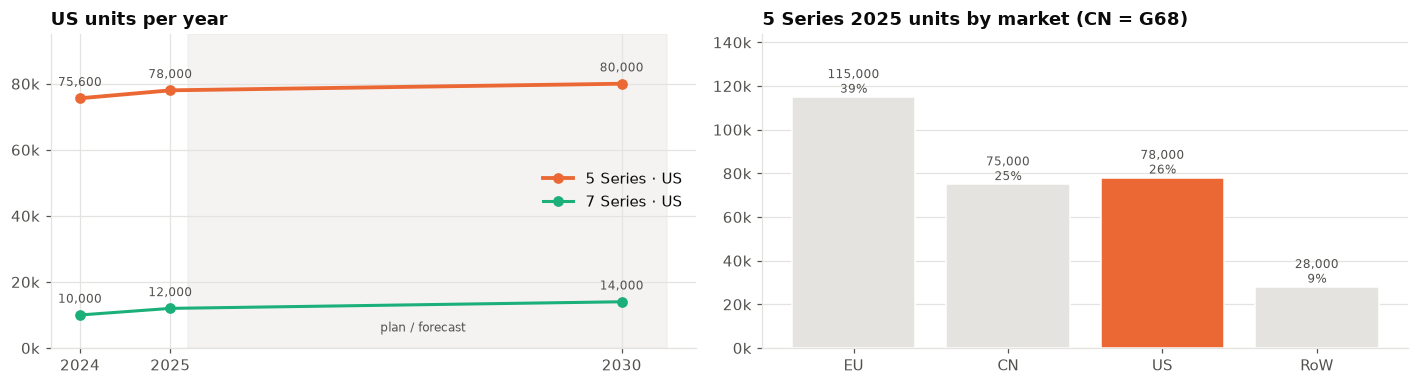

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))

ax = axes[0]
years = [2024, 2025, 2030]
ax.plot(years, us[YEARS].values, color=G60_COLOR, marker="o", linewidth=2.5, label="5 Series · US")
g70_us = sales[(sales.series == "G70") & (sales.market_code == "US")].iloc[0]
ax.plot(years, g70_us[YEARS].values, color=G70_COLOR, marker="o", linewidth=2, label="7 Series · US")
for y, v in zip(years, us[YEARS].values):
    ax.annotate(f"{v:,.0f}", (y, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=INK_2)
for y, v in zip(years, g70_us[YEARS].values):
    ax.annotate(f"{v:,.0f}", (y, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=INK_2)
ax.axvspan(2025.2, 2030.5, color=GRID, alpha=0.4, zorder=0)
ax.text(2027.8, 5000, "plan / forecast", ha="center", color=INK_2, fontsize=8)
ax.set_xticks(years)
ax.set_ylim(0, 95000)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_title("US units per year")
ax.legend(loc="center right")

ax = axes[1]
share25 = g60["volume_2025"] / g60["volume_2025"].sum()
colors = [G60_COLOR if m == "US" else GRID for m in share25.index]
ax.bar(share25.index, g60["volume_2025"], color=colors, edgecolor="white")
for i, (m, v) in enumerate(g60["volume_2025"].items()):
    ax.text(i, v, f"{v:,.0f}\n{share25[m]:.0%}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_ylim(0, g60["volume_2025"].max() * 1.25)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_title("5 Series 2025 units by market (CN = G68)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### 1.2 How much evidence per car sold?

A rough coverage metric: unique feedbacks per 1,000 units sold in 2025, per series and market. It shows where the
voice-of-customer data is dense enough to support requirements.

In [4]:
fb_all = pd.read_excel(DATA / "G60_feedback_hackathon.xlsx", dtype=str)
fb_g70 = pd.read_excel(DATA / "G70_feedback_hackathon.xlsx", dtype=str)
EU_COUNTRIES = {"GB", "SE", "DK", "FI", "NO", "FR", "LV", "ES", "DE", "IT", "NL", "BE", "AT", "PL"}


def market_of(country):
    return "US" if country == "US" else "EU" if country in EU_COUNTRIES else "CN" if country == "CN" else "RoW"


rows = []
for code, fb in [("G60", fb_all), ("G70", fb_g70)]:
    per_market = fb.drop_duplicates("ID")["Country"].map(market_of).value_counts()
    for m in MARKET_ORDER:
        units = sales[(sales.series == code) & (sales.market_code == m)]["volume_2025"].sum()
        n = per_market.get(m, 0)
        rows.append({"series": code, "market": m, "units 2025": units, "feedbacks": n,
                     "feedbacks per 1k units": n / units * 1000 if units else np.nan})
cov = pd.DataFrame(rows).set_index(["series", "market"])
cov.style.format({"units 2025": "{:,.0f}", "feedbacks": "{:,.0f}", "feedbacks per 1k units": "{:.1f}"}) \
    .background_gradient(subset="feedbacks per 1k units", cmap="Oranges")

**Sales: findings**

- The US is a **stable, mature market for the 5 Series**: 78k units in 2025, about 26 % of global 5 Series volume,
  with only +2.6 % planned growth to 2030 (+0.5 % a year, the slowest of the four markets). A successor here mostly
  **defends share**, so keeping today's owners (fix the pain points, protect the strengths) matters more than
  conquering new segments.
- The 5 Series is **87 % of the volume** of the three challenge series in the US (6.5× the 7 Series; no 1 Series).
- The US has the **densest 5 Series feedback**: about 46 feedbacks per 1k units sold, against about 1 in Europe and none in
  China. It is the only 5 Series market where requirements can rest on customers' own words. (The US 7 Series has even
  more per car, at 316 per 1k, because its sales are small.)
- **Missing:** no powertrain split (ICE vs i5 vs PHEV), no trim or price split, no monthly trend. Any powertrain
  weighting below uses the *feedback* mix, which is only a proxy.

---
## 2. Customer feedback: who is talking?

### 2.1 Load and tidy (US rows only)

In [5]:
fb_rows = fb_all[fb_all["Country"] == "US"].rename(columns={
    "Engine Type": "powertrain", "Feedback Type": "ftype",
    "Customer Feedback": "text", "Vfc level2 Name": "topic", "Vfc level3 Name": "nature",
}).copy()
fb_rows["Source"] = fb_rows["Source"].str.replace("Source ", "", regex=False)
fb_rows["powertrain"] = fb_rows["powertrain"].replace({"BEVE": "BEV"})
fb_rows["classified"] = fb_rows["topic"].notna() & (fb_rows["topic"] != "no_class_found")

feedbacks = (
    fb_rows.groupby("ID")
    .agg(Source=("Source", "first"), powertrain=("powertrain", "first"), text=("text", "first"),
         ftypes=("ftype", lambda s: frozenset(s.dropna())),
         topics=("topic", lambda s: frozenset(t for t in s.dropna() if t != "no_class_found")),
         n_labels=("ID", "size"))
    .reset_index()
)
feedbacks["text_len"] = feedbacks["text"].str.len()
cl = fb_rows[fb_rows["classified"]]

pd.Series({
    "rows (classifications)": len(fb_rows),
    "unique feedbacks": len(feedbacks),
    "feedbacks with ≥1 topic": (feedbacks["topics"].map(len) > 0).sum(),
    "unclassified feedbacks": (feedbacks["topics"].map(len) == 0).sum(),
    "classified rows": len(cl),
    "distinct topics": cl["topic"].nunique(),
    "median text length (chars)": int(feedbacks["text_len"].median()),
}).to_frame("US 5 Series").style.format("{:,}")

,US 5 Series
rows (classifications),"4,365"
unique feedbacks,"3,610"
feedbacks with ≥1 topic,"3,281"
unclassified feedbacks,329
classified rows,"3,826"
distinct topics,220
median text length (chars),155


### 2.2 Source, powertrain and feedback type

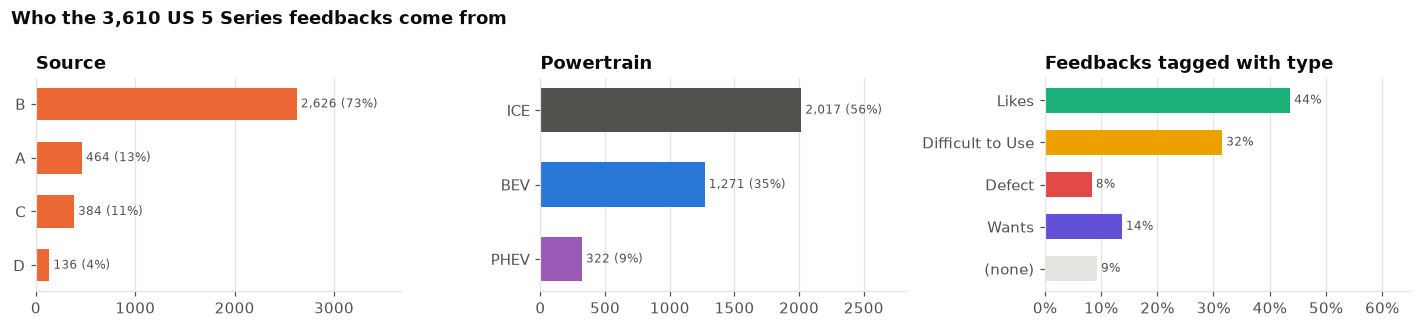

**Source × powertrain (unique feedbacks)**

powertrain,BEV,ICE,PHEV,All
Source,,,,
A,175,257,32,464
B,899,1479,248,2626
C,142,210,32,384
D,55,71,10,136
All,1271,2017,322,3610


In [6]:
n = len(feedbacks)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col, title in zip(axes[:2], ["Source", "powertrain"], ["Source", "Powertrain"]):
    vc = feedbacks[col].value_counts()
    cols = [PT_COLORS.get(i, G60_COLOR) for i in vc.index]
    ax.barh(vc.index[::-1], vc.values[::-1], color=cols[::-1], height=0.6)
    for y, v in enumerate(vc.values[::-1]):
        ax.text(v, y, f" {v:,} ({v / n:.0%})", va="center", fontsize=8, color=INK_2)
    ax.set_xlim(0, vc.max() * 1.4)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)

ax = axes[2]
tshare = {t: feedbacks["ftypes"].map(lambda x: t in x).mean() for t in FEEDBACK_TYPES}
tshare["(none)"] = feedbacks["ftypes"].map(len).eq(0).mean()
ax.barh(list(tshare)[::-1], list(tshare.values())[::-1],
        color=[TYPE_COLORS.get(t, GRID) for t in list(tshare)[::-1]], height=0.6)
for y, v in enumerate(list(tshare.values())[::-1]):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 0.65)
ax.set_title("Feedbacks tagged with type")
ax.grid(axis="y", visible=False)
fig.suptitle(f"Who the {n:,} US 5 Series feedbacks come from", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

src_pt = pd.crosstab(feedbacks["Source"], feedbacks["powertrain"], margins=True)
display(Markdown("**Source × powertrain (unique feedbacks)**"))
display(src_pt)

In [7]:
# Feedback-type mix per source and per powertrain: does the channel or the drivetrain change the tone?
def type_mix(by):
    out = pd.DataFrame({t: feedbacks.groupby(by)["ftypes"].apply(lambda s: s.map(lambda x: t in x).mean())
                        for t in FEEDBACK_TYPES})
    out.insert(0, "feedbacks", feedbacks.groupby(by).size())
    return out

display(Markdown("**Share of feedbacks tagged with each type, by source**"))
display(type_mix("Source").style.format({t: "{:.0%}" for t in FEEDBACK_TYPES})
        .background_gradient(subset=FEEDBACK_TYPES, cmap="Greys", axis=None))
display(Markdown("**…and by powertrain**"))
display(type_mix("powertrain").style.format({t: "{:.0%}" for t in FEEDBACK_TYPES})
        .background_gradient(subset=FEEDBACK_TYPES, cmap="Greys", axis=None))

**Share of feedbacks tagged with each type, by source**

,feedbacks,Likes,Difficult to Use,Defect,Wants
Source,,,,,
A,464,53%,27%,24%,19%
B,2626,51%,29%,5%,15%
C,384,0%,66%,16%,0%
D,136,0%,0%,0%,0%


**…and by powertrain**

,feedbacks,Likes,Difficult to Use,Defect,Wants
powertrain,,,,,
BEV,1271,42%,30%,10%,15%
ICE,2017,45%,32%,7%,12%
PHEV,322,43%,33%,8%,16%


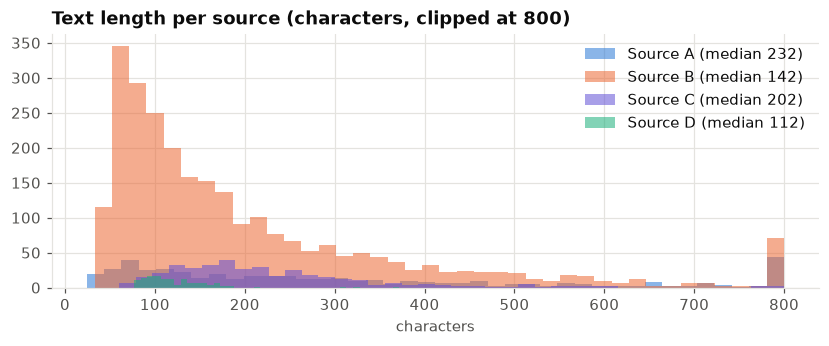

In [8]:
fig, ax = plt.subplots(figsize=(9, 3))
for src, color in zip("ABCD", ["#2a78d6", G60_COLOR, "#6250d6", "#1baf7a"]):
    lens = feedbacks.loc[feedbacks.Source == src, "text_len"].clip(upper=800)
    ax.hist(lens, bins=40, alpha=0.55, color=color, label=f"Source {src} (median {lens.median():.0f})")
ax.set_title("Text length per source (characters, clipped at 800)")
ax.set_xlabel("characters")
ax.legend()
plt.show()

**Who is talking: findings**

- **Source B (dealer/call-centre paraphrase) is 73 %** of the data. Its text is short and third-person ("Customer
  stated…"), so it tells us *what* is wrong more than *why* or how badly. Severity comes from Source C (§5.1).
- **Source C** is the critical channel: 66 % of its feedbacks are tagged Difficult to Use, and it carries self-rated
  severity. **Source D has no feedback-type tags at all**; its polarity is in the text (§5.2).
- **35 % of feedback is from i5 (BEV) owners**, so EV topics can be analysed. This is the feedback mix, not the sales mix.
- Tone is similar across powertrains. About 45 % of feedbacks contain a Like and about 31 % a Difficult-to-Use, but only about 8 % a
  Defect. The US story is mostly about **usability, not broken parts**.

---
## 3. What customers talk about

**Net sentiment per topic** = (Likes − Difficult to Use − Defect − Wants) / all classified rows of the topic.
Wants counts as negative because it marks something the car doesn't do today. **Pain** = Difficult to Use + Defect rows.

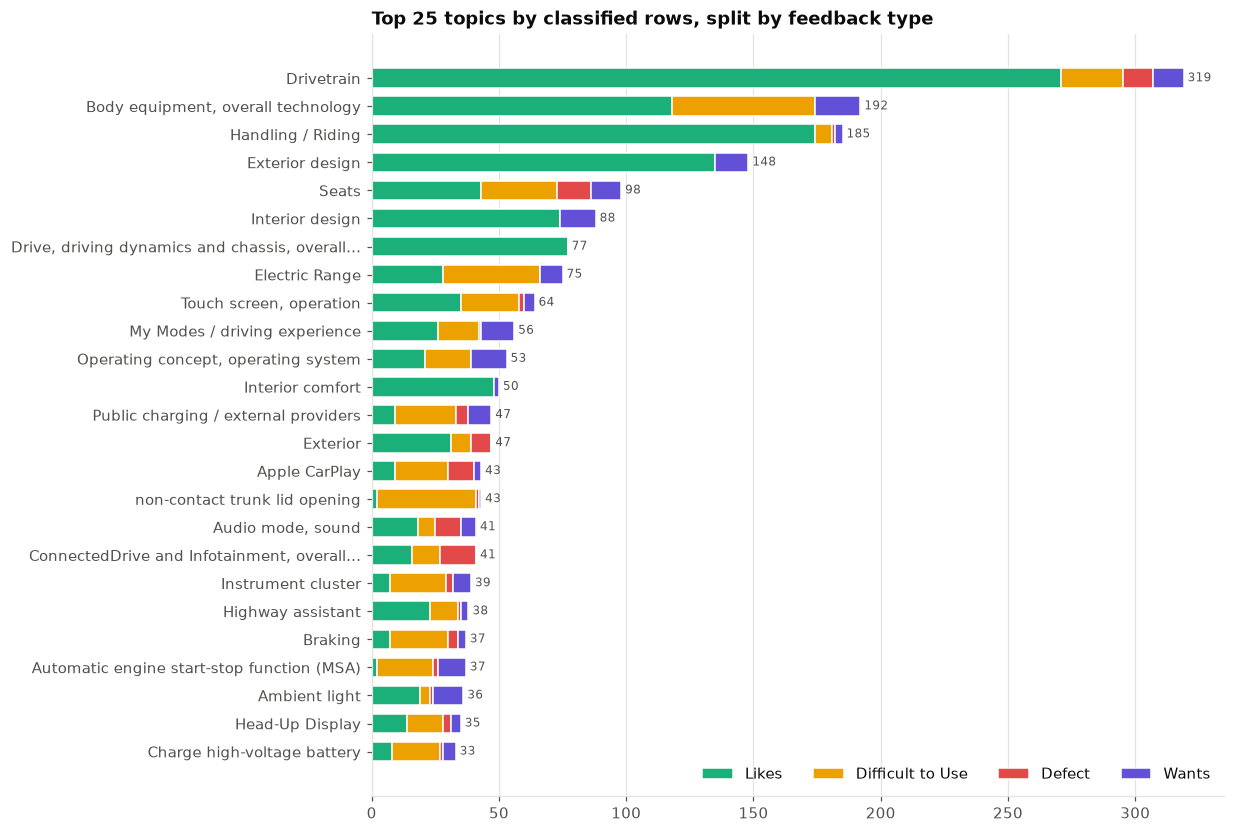

In [9]:
def topic_table(rows, min_rows=10):
    t = rows.pivot_table(index="topic", columns="ftype", values="ID", aggfunc="count", fill_value=0)
    t = t.reindex(columns=FEEDBACK_TYPES, fill_value=0)
    t["total"] = t.sum(axis=1)
    t["feedbacks"] = rows.groupby("topic")["ID"].nunique()
    t["net_sentiment"] = (t["Likes"] - t[["Difficult to Use", "Defect", "Wants"]].sum(axis=1)) / t["total"]
    t["pain"] = t[["Difficult to Use", "Defect"]].sum(axis=1)
    return t[t["total"] >= min_rows].sort_values("total", ascending=False)


topics = topic_table(cl)

top = topics.head(25)[FEEDBACK_TYPES].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 9))
left = np.zeros(len(top))
for ft in FEEDBACK_TYPES:
    ax.barh([short(i, 50) for i in top.index], top[ft], left=left, color=TYPE_COLORS[ft], label=ft,
            height=0.7, edgecolor="white", linewidth=1)
    left += top[ft].values
for y, v in enumerate(left):
    ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8, color=INK_2)
ax.set_title("Top 25 topics by classified rows, split by feedback type")
ax.legend(ncol=4, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

In [10]:
views = {
    "Most liked (Likes)": topics.sort_values("Likes", ascending=False)["Likes"],
    "Biggest pain (DtU + Defect)": topics.sort_values("pain", ascending=False)["pain"],
    "Most wanted (Wants)": topics.sort_values("Wants", ascending=False)["Wants"],
}
side = pd.concat([pd.DataFrame({(k, "topic"): v.head(12).index, (k, "rows"): v.head(12).values})
                  for k, v in views.items()], axis=1)
side.index = range(1, 13)
side

Most liked (Likes)                               Biggest pain (DtU + Defect)       \
                                                      topic rows                                                topic rows   
1                                                Drivetrain  271                   Body equipment, overall technology   56   
2                                         Handling / Riding  174                                                Seats   43   
3                                           Exterior design  135                        non-contact trunk lid opening   40   
4                        Body equipment, overall technology  118                                       Electric Range   38   
5   Drive, driving dynamics and chassis, overall technology   77                                           Drivetrain   36   
6                                           Interior design   74                                        Apple CarPlay   31   
7                                          Interior comfort   48                 Public charging / external providers   29   
8                                                     Seats   43                                              Braking   27   
9                                   Touch screen, operation   35                               Vehicle, lock / unlock   26   
10                                                 Exterior   31  ConnectedDrive and Infotainment, overall technology   25   
11                                           Electric Range   28                                   Instrument cluster   25   
12                               Space / spatial impression   27                              Touch screen, operation   25   

                           Most wanted (Wants)       
                                         topic rows  
1           Body equipment, overall technology   18  
2          Operating concept, operating system   14  
3                              Interior design   14  
4                My Modes / driving experience   13  
5                              Exterior design   13  
6                                   Drivetrain   12  
7                                        Seats   12  
8                                Ambient light   12  
9                          Panorama glass roof   12  
10  Automatic engine start-stop function (MSA)   11  
11                              Electric Range    9  
12                              Comfort Access    9

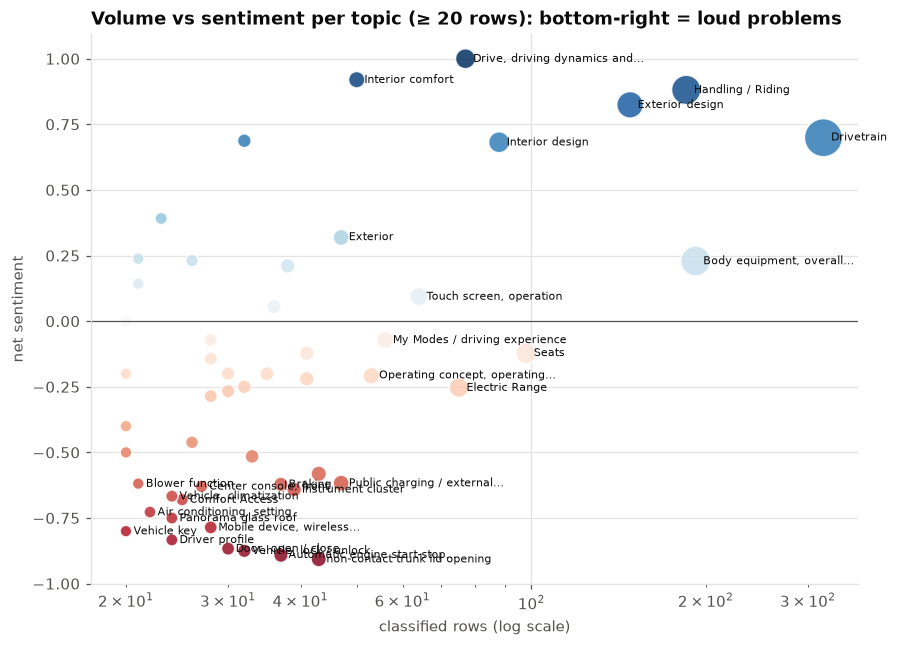

**Most negative topics with ≥ 20 rows**

ftype,Likes,Difficult to Use,Defect,Wants,total,net_sentiment
topic,,,,,,
non-contact trunk lid opening,2,39,1,1,43,-0.91
Automatic engine start-stop function (MSA),2,22,2,11,37,-0.89
"Vehicle, lock / unlock",2,22,4,4,32,-0.88
"Door, open / close",2,12,8,8,30,-0.87
Driver profile,2,18,1,3,24,-0.83
Vehicle key,2,6,7,5,20,-0.80
"Mobile device, wireless charging",3,10,11,4,28,-0.79
Panorama glass roof,3,4,5,12,24,-0.75
"Air conditioning, setting",3,11,0,8,22,-0.73


In [11]:
fig, ax = plt.subplots(figsize=(9, 6.5))
t = topics[topics["total"] >= 20]
sizes = t["feedbacks"] / t["feedbacks"].max() * 600 + 20
sc = ax.scatter(t["total"], t["net_sentiment"], s=sizes, c=t["net_sentiment"], cmap="RdBu", vmin=-1, vmax=1,
                edgecolor="white", alpha=0.85)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_xscale("log")
for topic, r in t.iterrows():
    if r["total"] >= 45 or r["net_sentiment"] <= -0.6:
        ax.annotate(short(topic, 30), (r["total"], r["net_sentiment"]), fontsize=7, xytext=(5, 0),
                    textcoords="offset points", va="center")
ax.set_xlabel("classified rows (log scale)")
ax.set_ylabel("net sentiment")
ax.set_title("Volume vs sentiment per topic (≥ 20 rows): bottom-right = loud problems")
plt.show()

display(Markdown("**Most negative topics with ≥ 20 rows**"))
topics[topics["total"] >= 20].sort_values("net_sentiment").head(15)[FEEDBACK_TYPES + ["total", "net_sentiment"]] \
    .style.format({"net_sentiment": "{:+.2f}"}).background_gradient(subset="net_sentiment", cmap="RdBu", vmin=-1, vmax=1)

### 3.1 What exactly do customers want? (level-3 nature of Wants and pain rows)

In [12]:
w = cl[cl["ftype"] == "Wants"]
display(Markdown(f"**Wants: top topic × request type** ({len(w)} rows)"))
display(w.groupby(["topic", "nature"]).size().sort_values(ascending=False).head(15).to_frame("rows"))

p = cl[cl["ftype"].isin(["Difficult to Use", "Defect"])]
display(Markdown(f"**Pain: what kind of problem, overall** ({len(p)} rows)"))
display(p.groupby(["ftype", "nature"]).size().sort_values(ascending=False).head(15).to_frame("rows"))

**Wants: top topic × request type** (532 rows)

,,rows
topic,nature,
"Operating concept, operating system",Customer request: usability,14
Exterior design,Customer request: design,13
"Body equipment, overall technology",Dislike: price-performance ratio,12
Automatic engine start-stop function (MSA),Permanent switch-off not possible,10
Electric Range,Customer request: function,9
Interior design,Customer request: design,9
Panorama glass roof,Customer request: function,9
Frunk,Customer request: function,8
Drivetrain,Customer request: performance,8


**Pain: what kind of problem, overall** (1594 rows)

rows
ftype            nature                                      
Difficult to Use Not user-friendly                        909
Defect           Malfunction                              224
                 Damage                                    59
Difficult to Use insufficient storage space                54
Defect           Noise                                     35
Difficult to Use Range, not OK                             34
                 Not comfortable                           30
                 Ergonomics do not appeal                  22
                 Dirty contamination                       20
                 Size not user friendly                    15
                 Information / accuracy insufficient       15
Defect           Connection fault                          15
Difficult to Use Noise                                     15
                 Effect, power not OK                      12
                 Drive power/driving performance not OK     9

### 3.2 Topic co-occurrence

Many verbatims raise several topics. Pairs that often appear together show which topics customers experience as one
thing, which helps to bundle requirements.

In [13]:
from itertools import combinations
from collections import Counter

pairs = Counter()
for ts in feedbacks["topics"]:
    for a, b in combinations(sorted(ts), 2):
        pairs[(a, b)] += 1
co = pd.DataFrame([(a, b, c) for (a, b), c in pairs.most_common(15)], columns=["topic A", "topic B", "feedbacks"])
co

,topic A,topic B,feedbacks
0,"Drive, driving dynamics and chassis, overall technology",Drivetrain,14
1,Drivetrain,Handling / Riding,10
2,Drivetrain,Seats,7
3,"Body equipment, overall technology","Drive, driving dynamics and chassis, overall technology",6
4,"Drive, driving dynamics and chassis, overall technology",Seats,6
5,Drivetrain,My Modes / driving experience,6
6,"Body equipment, overall technology",Seats,5
7,Braking,Drivetrain,5
8,"Drive, driving dynamics and chassis, overall technology",My Modes / driving experience,5
9,"Drive, driving dynamics and chassis, overall technology",Handling / Riding,5


**Topics: findings**

- **Protect:** drivetrain (271 Likes rows), handling/riding (174) and exterior design (135) dominate praise.
- **Loudest pain:** "Body equipment, overall technology" (too much tech to learn), seats, the **non-contact trunk
  opening**, electric range, CarPlay, public charging, braking feel/noise and lock/unlock.
- **Most one-sided negative topics are everyday access and convenience:** non-contact trunk (−0.91), auto start-stop
  (−0.89), lock/unlock (−0.88), doors (−0.87), driver profile (−0.83), key (−0.80) and wireless phone charging (−0.79).
  These are small, frequent annoyances, not breakdowns.
- **"Not user-friendly" is 57 % of all pain rows** (909 of 1,594). Malfunctions are 14 %.
- **Wants** are about making existing things simpler or switchable: operating-concept usability, a permanent switch-off
  for auto start-stop, more range, design changes, panorama roof, frunk and Comfort Access functions.
- Co-occurrence is dominated by driving topics (drivetrain + chassis + handling), so customers praise the drive as one
  thing.

---
## 4. Powertrain: is the i5 a different customer?

Lift = topic share among BEV rows / topic share among ICE rows (with +1 smoothing on the counts). A lift above 1 means
the topic is over-represented in i5 feedback.

In [14]:
sh = cl.groupby(["topic", "powertrain"]).size().unstack(fill_value=0)
counts = sh.copy()
sm = (sh + 1) / (sh + 1).sum()
lift = pd.DataFrame({
    "BEV rows": counts["BEV"], "ICE rows": counts["ICE"], "PHEV rows": counts["PHEV"],
    "BEV/ICE lift": sm["BEV"] / sm["ICE"], "PHEV/ICE lift": sm["PHEV"] / sm["ICE"],
})
display(Markdown("**Topics most over-represented in i5 (BEV) feedback** (≥ 15 BEV rows)"))
display(lift[lift["BEV rows"] >= 15].sort_values("BEV/ICE lift", ascending=False).head(12)
        .style.format({"BEV/ICE lift": "{:.1f}×", "PHEV/ICE lift": "{:.1f}×"}))
display(Markdown("**Topics most over-represented in ICE feedback** (≥ 15 ICE rows)"))
display(lift[lift["ICE rows"] >= 15].sort_values("BEV/ICE lift").head(10)
        .style.format({"BEV/ICE lift": "{:.1f}×", "PHEV/ICE lift": "{:.1f}×"}))

**Topics most over-represented in i5 (BEV) feedback** (≥ 15 BEV rows)

,BEV rows,ICE rows,PHEV rows,BEV/ICE lift,PHEV/ICE lift
topic,,,,,
Electric Range,61,0,14,90.4×,62.6×
Public charging / external providers,46,1,0,34.3×,2.1×
"Wallbox, charging / home charging",16,0,3,24.8×,16.7×
Opening/closing charging socket cover,15,0,2,23.3×,12.5×
Charge high-voltage battery,23,2,8,11.7×,12.5×
Highway assistant,21,12,5,2.5×,1.9×
Navigation,15,13,4,1.7×,1.5×
Interior comfort,22,20,8,1.6×,1.8×
"Audio mode, sound",17,18,6,1.4×,1.5×


**Topics most over-represented in ICE feedback** (≥ 15 ICE rows)

,BEV rows,ICE rows,PHEV rows,BEV/ICE lift,PHEV/ICE lift
topic,,,,,
Automatic engine start-stop function (MSA),0,37,0,0.0×,0.1×
(Active) cruise control,4,25,1,0.3×,0.3×
"Vehicle, lock / unlock",4,22,6,0.3×,1.3×
Owner's Manual,3,15,2,0.4×,0.8×
"Driver assistance, automated driving, overall technology",4,17,0,0.4×,0.2×
Wheels / tires,6,21,1,0.5×,0.4×
"Touch screen, operation",15,46,3,0.5×,0.4×
"Air conditioning, setting",5,16,1,0.5×,0.5×
Exterior,12,34,1,0.5×,0.2×


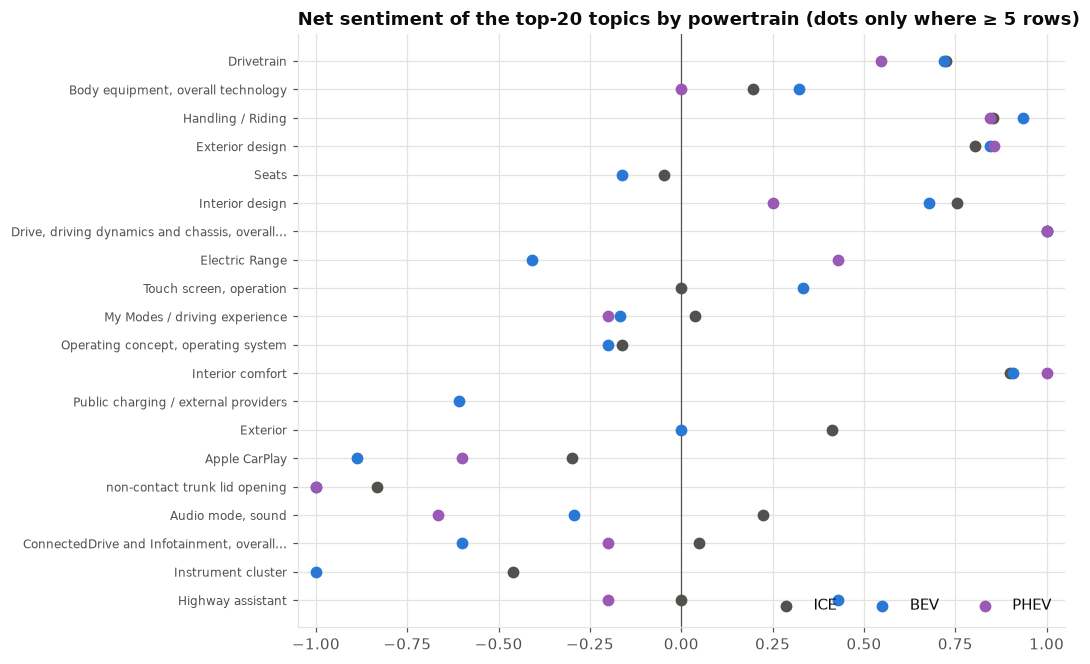

In [15]:
pt_net = pd.DataFrame({pt: topic_table(cl[cl.powertrain == pt], min_rows=1)["net_sentiment"] for pt in ["ICE", "BEV", "PHEV"]})
pt_n = pd.DataFrame({pt: topic_table(cl[cl.powertrain == pt], min_rows=1)["total"] for pt in ["ICE", "BEV", "PHEV"]})
keep = topics.head(20).index
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(keep))
for i, pt in enumerate(["ICE", "BEV", "PHEV"]):
    vals = pt_net.reindex(keep)[pt]
    ok = pt_n.reindex(keep)[pt].fillna(0) >= 5
    ax.scatter(vals[ok], y[ok.values], color=PT_COLORS[pt], s=45, label=pt, zorder=3)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_yticks(y, [short(k, 45) for k in keep], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(-1.05, 1.05)
ax.set_title("Net sentiment of the top-20 topics by powertrain (dots only where ≥ 5 rows)")
ax.legend(ncol=3, loc="lower right")
plt.show()

**Powertrain: findings**

- **i5-specific:** electric range, public charging, home charging/wallbox, the charging-socket cover and HV battery
  charging are almost exclusively BEV (and partly PHEV) topics. They are requirements for the electric derivative only.
- **ICE-leaning:** auto start-stop (37 ICE rows, 0 BEV), active cruise control, lock/unlock, the owner's manual and
  touch-screen operation (0.5× in BEV). Several of these complaints are about operating the car, not about the engine.
- Shared across all drivetrains: seats, CarPlay, overall tech complexity and climate settings. These are platform-level requirements.
- PHEV is small (322 feedbacks), so treat its numbers as directional only.

---
## 5. Channel deep dives

### 5.1 Source C: quality survey with self-reported severity

Source C texts follow the pattern *"I had a <severity> problem with <item> - <symptom>: "<verbatim>""*. This is the
only place in the data where **customers rate how bad a problem is**.

kind,problem report,NPS reason,message to BMW
Source C feedbacks,320,37,27


severity,very minor,minor,unspecified,serious,very serious
problem reports,50,84,85,64,37


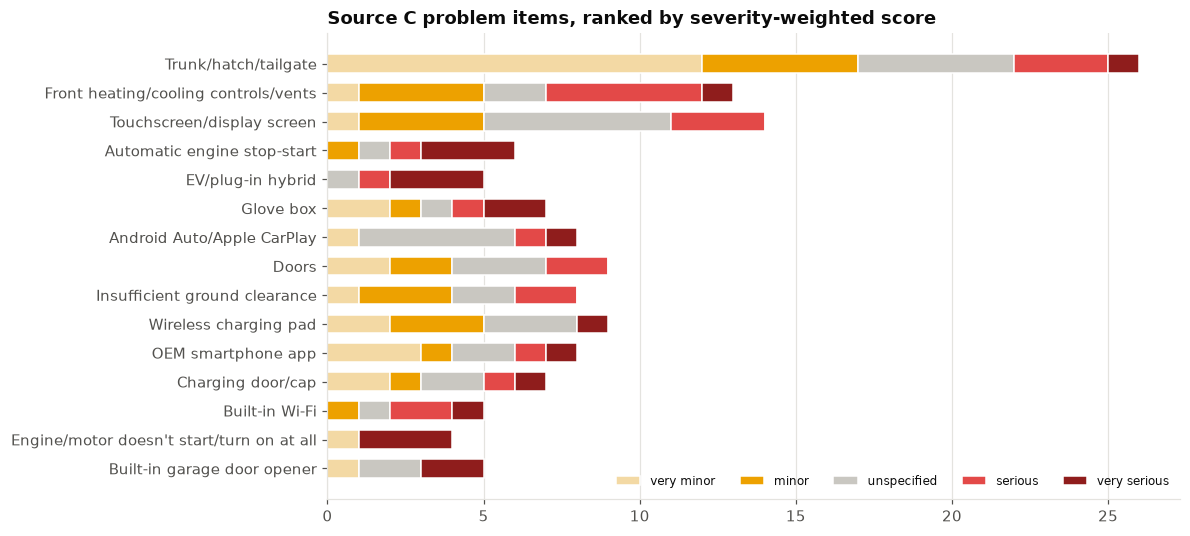

,reports,severity_score,serious_or_worse
item,,,
Trunk/hatch/tailgate,26,49,4
Front heating/cooling controls/vents,13,38,6
Touchscreen/display screen,14,33,3
Automatic engine stop-start,6,23,4
EV/plug-in hybrid,5,21,4
Glove box,7,20,3
Android Auto/Apple CarPlay,8,20,2
Doors,9,20,2
Insufficient ground clearance,8,19,2


In [16]:
c = feedbacks[feedbacks["Source"] == "C"].copy()
m = c["text"].str.extract(r"I had an? (?:(very minor|minor|serious|very serious) )?problem with (.+?)(?: - (.+?))?:\s*\"")
c["severity"] = m[0].fillna("unspecified").where(m[1].notna())
c["item"] = m[1].str.strip()
c["symptom"] = m[2].str.strip()
c["kind"] = np.select(
    [c["item"].notna(), c["text"].str.contains("nps rating", case=False),
     c["text"].str.contains("one comment", case=False)],
    ["problem report", "NPS reason", "message to BMW"], default="other")
display(c["kind"].value_counts().to_frame("Source C feedbacks").T)

SEV_ORDER = ["very minor", "minor", "unspecified", "serious", "very serious"]
SEV_WEIGHT = {"very minor": 1, "minor": 2, "unspecified": 2, "serious": 4, "very serious": 5}
probs = c[c["kind"] == "problem report"].copy()
probs["sev_weight"] = probs["severity"].map(SEV_WEIGHT)
display(probs["severity"].value_counts().reindex(SEV_ORDER, fill_value=0).to_frame("problem reports").T)

items = probs.groupby("item").agg(reports=("ID", "size"), severity_score=("sev_weight", "sum"),
                                  serious_or_worse=("severity", lambda s: s.isin(["serious", "very serious"]).sum()))
items = items.sort_values("severity_score", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5.5))
sev_ct = pd.crosstab(probs["item"], probs["severity"]).reindex(items.index).reindex(columns=SEV_ORDER, fill_value=0).iloc[::-1]
sev_colors = ["#f3d9a4", "#eda100", "#c9c7c1", "#e34948", "#8f1d1c"]
left = np.zeros(len(sev_ct))
for sev, col in zip(SEV_ORDER, sev_colors):
    ax.barh([short(i, 50) for i in sev_ct.index], sev_ct[sev], left=left, color=col, label=sev, height=0.65,
            edgecolor="white")
    left += sev_ct[sev].values
ax.set_title("Source C problem items, ranked by severity-weighted score")
ax.legend(ncol=5, loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
plt.show()
items

In [17]:
display(Markdown("**Most common item + symptom combinations**"))
display(probs.groupby(["item", "symptom"]).size().sort_values(ascending=False).head(12).to_frame("reports"))

display(Markdown("**NPS reasons and messages to BMW: sample** (the survey asks the customer directly)"))
for _, r in c[c["kind"].isin(["NPS reason", "message to BMW"])].sample(8, random_state=3).iterrows():
    quote = r["text"].split(':', 1)[-1].strip().strip('"')
    display(Markdown(f"- `{r.ID}` ({r.powertrain}, {r.kind}): {short(quote, 240)}"))

**Most common item + symptom combinations**

,,reports
item,symptom,
Trunk/hatch/tailgate,Touch-free sensor doesn't work consistently/DTU,20
Front heating/cooling controls/vents,DTU/poorly located,12
Touchscreen/display screen,DTU,9
Charging door/cap,Hard to open/close,7
Glove box,DTU,7
Doors,Handle/latch/release - DTU,6
Head-up display,DTU/display difficult to see,6
Wireless charging pad,Broken/works inconsistently,6
Android Auto/Apple CarPlay,Not working/connectivity problems,6


**NPS reasons and messages to BMW: sample** (the survey asks the customer directly)

- `G60-0427` (BEV, NPS reason): Comfort, design, interface, reliability.

- `G60-3709` (ICE, message to BMW): I really wish I knew how to use the dashcam and watch the front and rear recordings

...

- `G60-3847` (ICE, NPS reason): Outstanding in performance, comfort, and overall style.

- `G60-3183` (BEV, message to BMW): Please continue pushing ahead and making every new model year the best yet, BMW is still the Ultimate Driving Machine. This is my 5th BMW 5 Series, and I also owned an M Roadster before. Awsome.

- `G60-1668` (ICE, NPS reason): very solid car with great mileage

- `G60-2153` (BEV, message to BMW): range anxiety is definitely there. i really want the next version to have more range. we also need more level 3 chargers and the ones out there should actually function. at electrify america i almost never reach or hold the 205 kw rate. my…

- `G60-2581` (ICE, message to BMW): I wish the blind spot detection would give an audible alert when it senses a car in the lane I am moving to, not just the flashing light.

### 5.2 Source D: "the one thing I love most / could be most improved about …"

A structured survey: each answer is tied to an **area** of the car and a **polarity** (love vs improve).

In [18]:
d = feedbacks[feedbacks["Source"] == "D"].copy()
m = d["text"].str.extract(r"^(.*?)\.?\s*That is (?:the )?one thing (?:I |do you )?(love most|could be most improved) about (?:the )?(.+?)(?: of| in)? (?:my|your)")
d["answer"], d["polarity"], d["area"] = m[0], m[1].map({"love most": "love", "could be most improved": "improve"}), m[2]
d["area"] = d["area"].str.replace(r"^(?:the )", "", regex=True).str.strip()
area = pd.crosstab(d["area"], d["polarity"]).reindex(columns=["love", "improve"], fill_value=0)
area["improve share"] = area["improve"] / area.sum(axis=1)
display(area.sort_values("improve share", ascending=False).style.format({"improve share": "{:.0%}"})
        .background_gradient(subset="improve share", cmap="Reds", vmin=0, vmax=1))
display(Markdown("**'Could be most improved' answers**"))
for _, r in d[d["polarity"] == "improve"].iterrows():
    display(Markdown(f"- *{r.area}* ({r.powertrain}): {short(r.answer, 200)}"))

polarity,love,improve,improve share
area,,,
setting up and starting,2,2,50%
interior,17,13,43%
engine/motor,8,5,38%
infotainment system,13,6,32%
getting in/out,17,5,23%
driving comfort,11,2,15%
driving feel,24,1,4%
feeling of safety you get driving,2,0,0%
exterior styling,8,0,0%


**'Could be most improved' answers**

- *interior* (ICE): the head rests are too short

- *engine/motor* (ICE): visible tailpipes

- *interior* (PHEV): Maybe add more leather and lighting customization.

...

- *interior* (ICE): there isnt a little compartment anymore for keeping loose change.

- *interior* (BEV): central console feels a bit tight, and the standard graphic backgrounds are a little too edgy for me.

- *interior* (ICE): improved cupholders

- *infotainment system* (BEV): Infotainment is great overall, just a bit complex and it's tough to find things.

- *driving comfort* (BEV): cabin noise level feels way too high

### 5.3 Verbatims behind the top pain topics

Random samples (fixed seed) of Difficult-to-Use / Defect / Wants feedback for the eight topics with the most pain rows.
These quotes are the kind of evidence a PM should see next to each requirement.

In [19]:
fb_idx = feedbacks.set_index("ID")


def sample_verbatims(topic, k=4, seed=0):
    ids = cl[(cl["topic"] == topic) & cl["ftype"].isin(["Difficult to Use", "Defect", "Wants"])]["ID"].unique()
    picks = fb_idx.loc[ids].sample(min(k, len(ids)), random_state=seed)
    lines = [f"- `{i}` ({r.Source}, {r.powertrain}): {short(r.text, 260)}" for i, r in picks.iterrows()]
    display(Markdown(f"**{topic}**: {len(ids)} critical feedbacks\n\n" + "\n".join(lines)))


for topic in topics.sort_values("pain", ascending=False).index[:8]:
    sample_verbatims(topic)

**Body equipment, overall technology**: 74 critical feedbacks

- `G60-3002` (A, ICE): overall the car is very nice, but i'm not a fan of losing all the buttons and knobs and having to dig through the computer to find things. auto start/stop should either be gone or at least have a way to turn it off permanently. the fact there is no automatic…
- `G60-3189` (B, ICE): Customer stated there is so much equipment on the vehicle that it can be a bit difficult to figure out how everything works. Customer stated his wife is learning as she goes and is exploring the features over time. Customer stated the dealership told them…
- `G60-1310` (A, BEV): i had the earlier 5 series g30 and this one clearly comes with fewer features. the multi contour seats are changed and dont offer as many adjustments anymore. there is also no comfort access for the back doors. it really feels like cost cutting. on a 90k+ car…
- `G60-2479` (B, BEV): Customer stated he is not yet using the car to its full potential and that he still has a lot to learn. Writer offered assistance and documented the interaction under the appropriate case codes.

**Seats**: 49 critical feedbacks

- `G60-2041` (A, ICE): i do like all the automation in the bmw, but i wish there were a few more manual controls in the car. i'm not tall, and the seat extension is obviously meant for taller drivers. it should really be possible to retract that extension, especially for the driver…
- `G60-0320` (A, BEV): this car ticks almost all the boxes for me. the key thing is that it is genuinely fun to drive. on top of that, the purchase price felt competitive and the overall value for a new car seemed good. the downside is the complexity of the technology. it is not…
- `G60-1853` (A, ICE): for me and my husband, who does most of the driving, the biggest negative is having nearly all the controls on the touch screen. we just can't remember every symbol for everything. a lot of them we still don't recognize and feel like we need to go back to see…
- `G60-2595` (C, BEV): I had a very minor problem with Seats have insufficient range of adjustment: "Id prefer if it could sit a little higher. This isnt really an issue, more of a request.". Which Seat Insufficient Range?: Driver seat, Which Seat Control Insufficient Range?: Height

**non-contact trunk lid opening**: 41 critical feedbacks

- `G60-2959` (C, ICE): I had a very minor problem with Trunk/hatch/tailgate - Touch-free sensor doesn't work consistently/DTU: "Sensor not working"
- `G60-3564` (B, ICE): Customer stated the foot kick opening works for him less than half the time and he finds it ineffective. Customer stated that on his previous Mercedes Benz there was a foot wave to open, which he felt was much more forgiving than the current setup.
- `G60-3233` (B, ICE): Customer stated she struggles using the foot trunk opener, feeling it only works when her foot is placed very precisely and that it is hard when her arms are full, making her feel goofy repeating it. Writer advised the 5 Series kick-to-open is improved and…
- `G60-0931` (C, BEV): I had a problem with Trunk/hatch/tailgate - Touch-free sensor doesn't work consistently/DTU: "I wave my foot under the rear of the car and sometimes the trunk just does not open."

**Electric Range**: 46 critical feedbacks

- `G60-2291` (B, BEV): Customer asked what influences the vehicle's range. Writer explained that climate control usage, driving style, charging patterns, terrain, navigation use, the selected driving mode, and other elements can all impact range. Writer further advised that…
- `G60-2180` (B, BEV): Customer stated the roughly 300 mile range gives his wife range anxiety. Customer stated their family visit is about 305 miles, so they use the gasoline car for that trip. Customer stated a range closer to 400 miles would be good.
- `G60-2455` (B, BEV): Customer stated he would like the range of his BMW to be closer to what he had with his Tesla Model Y, wanting a similar driving distance on a charge.
- `G60-0498` (A, BEV): i'm not happy with the mileage i'm getting. there are a lot of extra features and functions that could be added into the idrive system, but there's no formal way for customers to propose these ideas. it comes across like bmw doesn't really care about customer…

**Drivetrain**: 48 critical feedbacks

- `G60-2880` (A, PHEV): overall it is an outstanding car. there are just a couple of things that really feel like cost cutting, and i honestly do not get why those choices were made. the biggest one is that the car cannot acclimatize while on the ice and instead will only use the…
- `G60-1024` (B, BEV): Customer commented that the vehicle gains speed extremely quickly and that this level of acceleration means they need to pay close attention when driving.
- `G60-2414` (B, ICE): Customer stated they had anticipated better gas mileage, referring to the trend of improvements from one model year to the next.
- `G60-2930` (B, ICE): Customer stated an update was installed and afterward the check engine light came on, so the vehicle is currently at the shop. Writer asked what the specific update was, and the customer said he was not really sure, only that the dealership mentioned the…

**Apple CarPlay**: 34 critical feedbacks

- `G60-1598` (B, BEV): Customer stated he is experiencing issues with his iPhone staying connected to the vehicle through Apple CarPlay. Customer stated he visited the dealership for assistance in making the connection more stable. Customer stated they discovered a Siri-related…
- `G60-2467` (A, BEV): great: * very comfortable and quiet. * excellent handling, with precise steering. * interior is practical and modern; quality has been great so far. * seats are comfy, veganza material feels nice. * good balance between real buttons and software controls. *…
- `G60-2845` (B, ICE): Customer stated that intermittently when wireless CarPlay connects, the skip track buttons on the steering wheel and center console do not respond. Customer stated the rotary dial will always advance to the next track with a click and never has an issue.…
- `G60-2075` (B, BEV): Customer stated it is difficult for him to move between CarPlay and iDrive, as he cannot always figure out where to change it.

**Public charging / external providers**: 38 critical feedbacks

- `G60-2490` (A, BEV): battery seems to run down fast. within just a couple months i was already dealing with electrical problems and drive train issues. plus not every charging station actually works, so trying to track down a reliable charger while traveling is very stressful.
- `G60-2983` (B, BEV): Customer stated Electrify America seems quite good and charges quickly when he is at the right station.
- `G60-1559` (A, BEV): i genuinely like the car a lot, but the one thing keeping me from giving it a 10 is that the range feels a little questionable on longer trips, which makes it more reliant on public chargers. and electrify america is just awful, no ifs, ands or buts. once…
- `G60-1551` (A, BEV): - the charge port door often will not open, even when the car is unlocked. i frequently have to restart and then shut off the car again just to get the charge port door to finally open. - the rear driver-side door often stays locked when i get out. - audio…

**Braking**: 29 critical feedbacks

- `G60-0403` (B, ICE): Customer reported that the vehicle has been producing a squeaking sound from the brakes after only about four weeks of ownership, and that the issue happens whenever the brake pedal is pressed. Customer stated the noise is loud and ongoing and that it makes…
- `G60-2840` (B, ICE): Customer reported that the car seems to use electric braking rather than hydraulic braking, and said it is basically impossible to come to a smooth stop without the car jerking forward. Customer described that even when pressing the brake pedal very gently…
- `G60-3150` (C, ICE): I had a minor problem with Excessive brake dust: "Like most German cars, there is a lot of brake dust collecting on the front wheels."
- `G60-1562` (A, PHEV): 1. forward collision warning and automatic emergency braking this car is supposed to come with standard forward collision warning and automatic emergency braking, but those features basically do not work. i have contacted your technical support several times,…

---
## 6. US customer study (2025)

103 attributes, each with the share of respondents per scale point, from *I Hate It* (1) to *I Love It* (7). We derive:

- **weighted mean** (1–7),
- **top-2 box** = Delightful + I Love It (enthusiasm),
- **bottom-3 box** = I Hate It + A Failure + Unsatisfactory (rejection).

Attributes are grouped into **domains** using the sheet's own "Overall …" headers. The G70 column (7 Series, same
survey) is the benchmark: same brand, same market, one class up.

In [20]:
STUDY = DATA / "F70_G60_G68_G70_customer_studies.xlsx"
US_SCALE = ["I Hate It", "A Failure", "Unsatisfactory", "Satisfactory", "Excellent", "Delightful", "I Love It"]
raw_us = pd.read_excel(STUDY, sheet_name="US_2025", header=None)

# Domain = the most recent "Overall …" attribute; a few headers in the sheet don't start with "Overall".
DOMAIN_STARTS = {"Overall exterior styling": "Exterior", "Overall driving performance": "Driving performance",
                 "Overall power and pickup": "Power", "Overall interior styling/ aesthetics": "Interior styling & quality",
                 "Overall comfort of the seats": "Seats", "Overall interior design / layout": "Space & practicality",
                 "Overall performance of climate control system": "Climate", "Overall performance of sound system": "Audio",
                 "Placement/ ease of reading and using controls": "Controls",
                 "Overall noise/vibration/harshness": "NVH & sound",
                 "Overall impression of durability/reliability": "Reliability", "Overall safety of the vehicle": "Safety",
                 "Overall value for money": "Value & ownership", "Overall brand image": "Brand",
                 "Overall driver assist features": "Driver assistance",
                 "Overall driver-vehicle interaction (HMI)": "HMI & infotainment",
                 "Overall environmental friendliness": "Other"}
# The block between "Braking" and "Overall value for money" mixes topics; assign those attributes one by one.
ATTR_DOMAIN = {"Warranty coverage": "Value & ownership", "Headlight function/ brightness": "Safety",
               "Technical innovations": "HMI & infotainment", "Level of standard equipment": "Value & ownership"}

recs, attribute, domain = [], None, None
for _, row in raw_us.iterrows():
    if pd.isna(row.iloc[0]):
        continue
    label = str(row.iloc[0]).strip()
    if label in US_SCALE:
        for col, code in {2: "G60", 3: "G70"}.items():
            recs.append((ATTR_DOMAIN.get(attribute, domain), attribute, code, label, float(row.iloc[col])))
    elif label != "Sample total":
        attribute = label
        domain = DOMAIN_STARTS.get(label, domain)
us_long = pd.DataFrame(recs, columns=["domain", "attribute", "series", "level", "share"])
dist = us_long.pivot_table(index=["domain", "attribute", "series"], columns="level", values="share", sort=False)[US_SCALE]
study = pd.DataFrame({
    "mean": (dist * np.arange(1, 8)).sum(axis=1) / dist.sum(axis=1),
    "top2": dist[["Delightful", "I Love It"]].sum(axis=1),
    "bottom3": dist[["I Hate It", "A Failure", "Unsatisfactory"]].sum(axis=1),
}).reset_index()
s60 = study[study.series == "G60"].set_index("attribute")
s70 = study[study.series == "G70"].set_index("attribute")
s60 = s60.assign(top2_vs_G70=s60["top2"] - s70["top2"], mean_vs_G70=s60["mean"] - s70["mean"],
                 is_overall=s60.index.str.startswith("Overall") | s60.index.isin(DOMAIN_STARTS))
print(f"{len(s60)} attributes in {s60['domain'].nunique()} domains; scale shares sum to "
      f"{dist.sum(axis=1).min():.3f}–{dist.sum(axis=1).max():.3f}")
s60.groupby("domain", sort=False).size().to_frame("attributes").T

103 attributes in 17 domains; scale shares sum to 1.000–1.000


domain,Exterior,Driving performance,Power,Interior styling & quality,Seats,Space & practicality,Climate,Audio,Controls,NVH & sound,Reliability,Safety,Value & ownership,HMI & infotainment,Brand,Driver assistance,Other
attributes,6,7,3,8,3,17,4,4,2,7,3,5,8,15,3,4,4


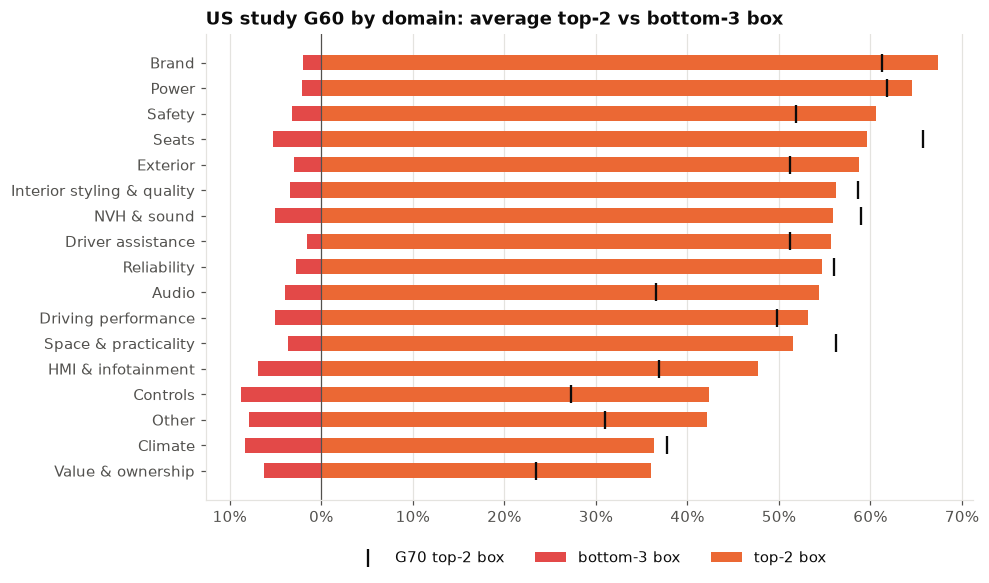

,attributes,mean,top2,bottom3,top2_vs_G70
domain,,,,,
Value & ownership,8,5.13,36%,6.3%,+12.6%
Climate,4,5.11,36%,8.3%,-1.4%
Other,4,5.14,42%,7.9%,+11.1%
Controls,2,5.16,42%,8.8%,+15.1%
HMI & infotainment,15,5.35,48%,6.9%,+10.8%
Space & practicality,17,5.54,52%,3.6%,-4.7%
Driving performance,7,5.62,53%,5.0%,+3.3%
Audio,4,5.60,54%,3.9%,+17.9%
Reliability,3,5.72,55%,2.8%,-1.3%


In [21]:
dom = s60.groupby("domain", sort=False).agg(attributes=("mean", "size"), mean=("mean", "mean"),
                                            top2=("top2", "mean"), bottom3=("bottom3", "mean"),
                                            top2_vs_G70=("top2_vs_G70", "mean")).sort_values("top2")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(dom.index, -dom["bottom3"], color="#e34948", height=0.6, label="bottom-3 box")
ax.barh(dom.index, dom["top2"], color=G60_COLOR, height=0.6, label="top-2 box")
ax.scatter(dom["top2"] - dom["top2_vs_G70"], dom.index, marker="|", s=150, color=INK, zorder=3,
           label="G70 top-2 box")
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.xaxis.set_major_formatter(lambda v, _: f"{abs(v) * 100:.0f}%")
ax.set_title("US study G60 by domain: average top-2 vs bottom-3 box")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.grid(axis="y", visible=False)
plt.show()
dom.style.format({"mean": "{:.2f}", "top2": "{:.0%}", "bottom3": "{:.1%}", "top2_vs_G70": "{:+.1%}"})

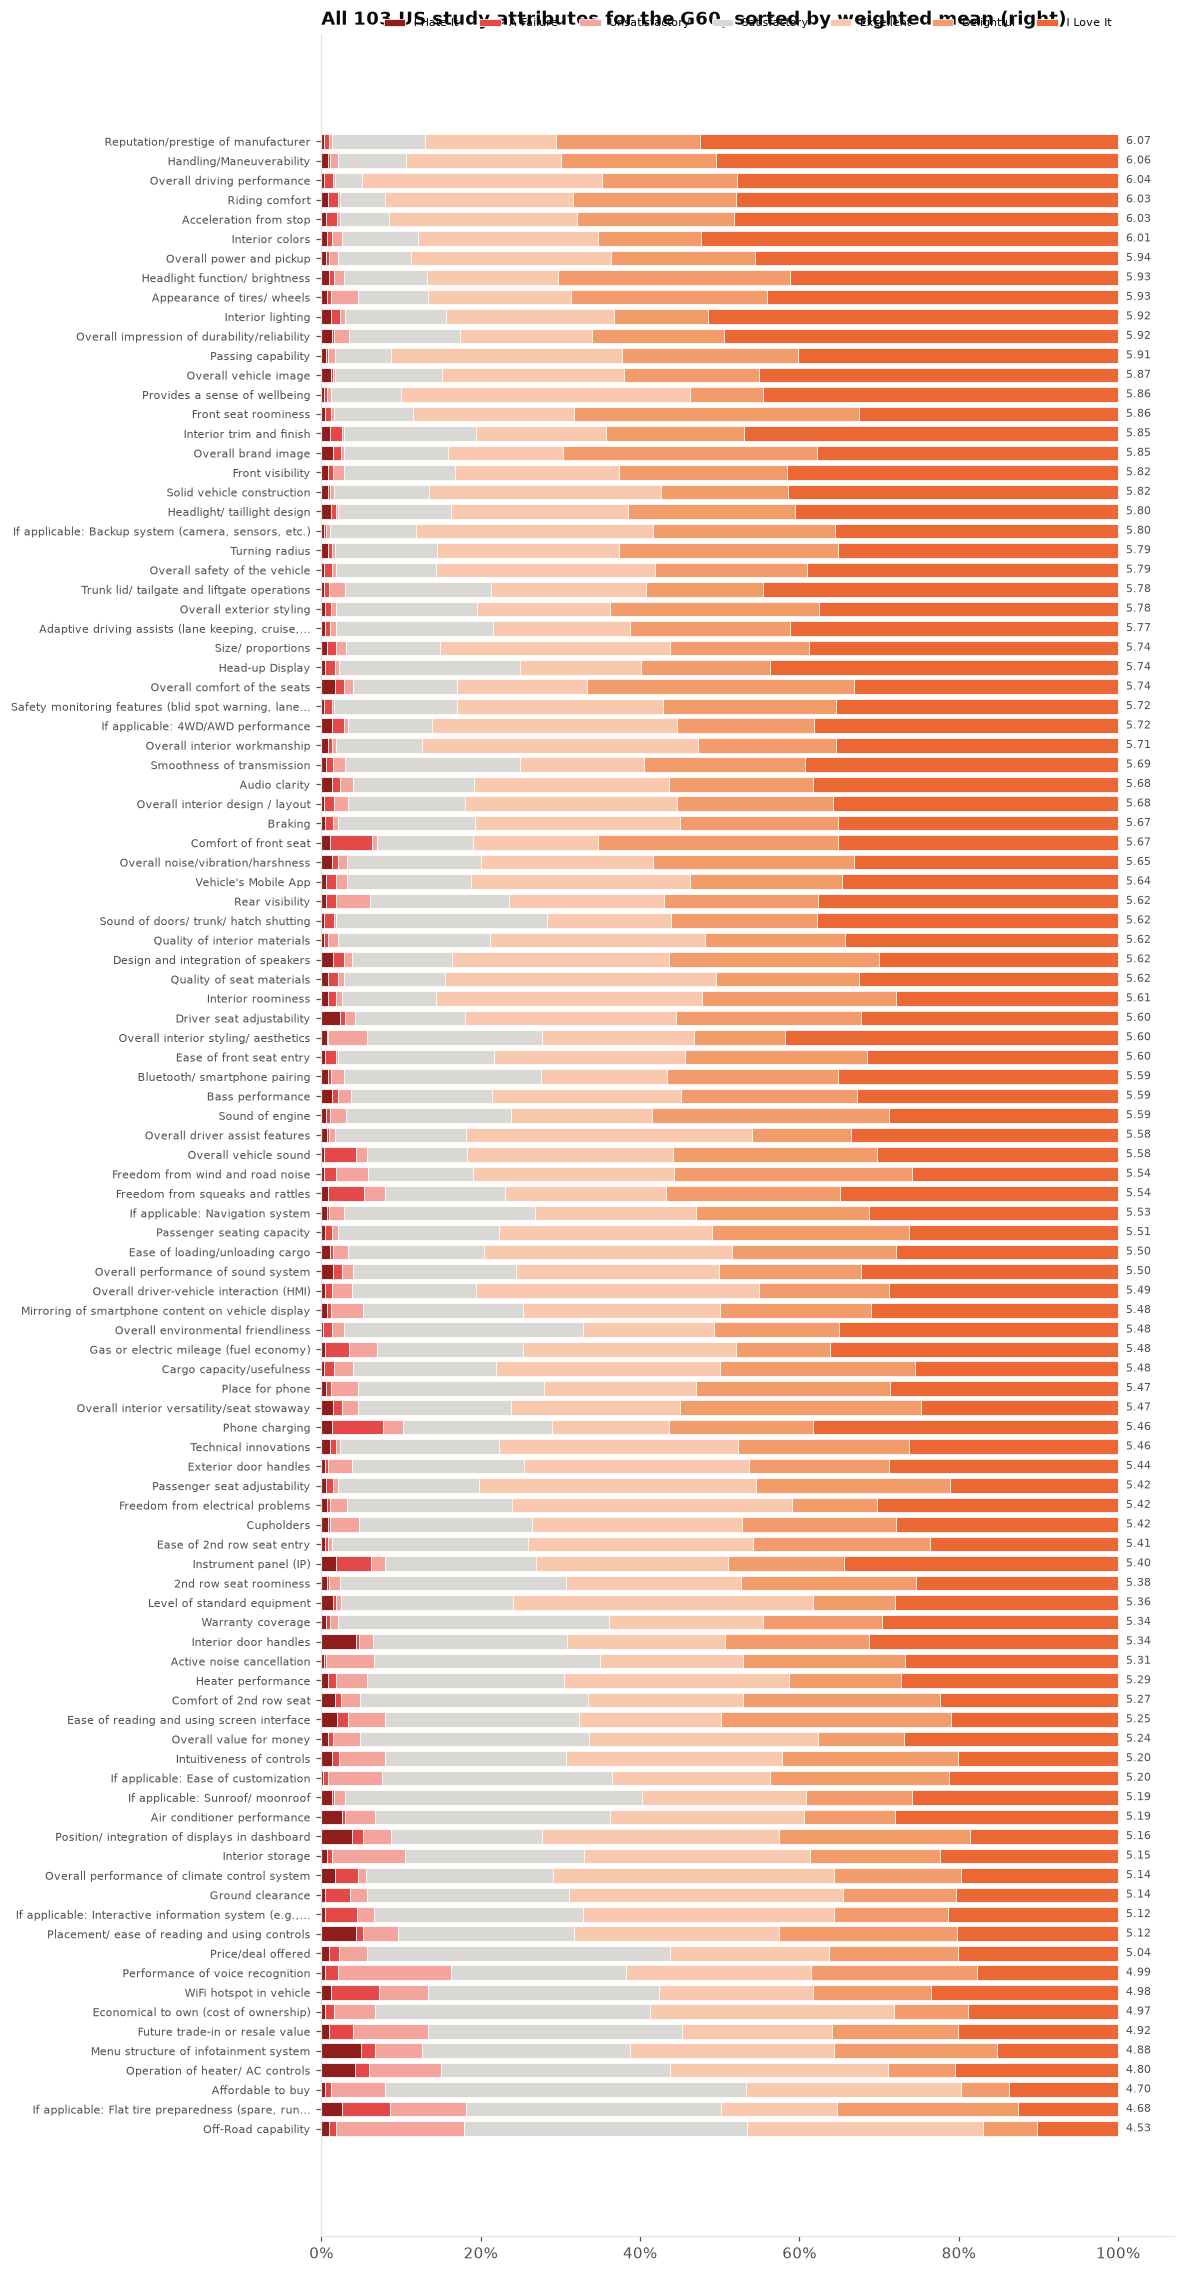

In [22]:
fig, ax = plt.subplots(figsize=(10, 26))
order = s60.sort_values("mean").index
cum = np.zeros(len(order))
scale_colors = ["#8f1d1c", "#e34948", "#f3a49c", "#d9d8d4", "#f8c9ae", "#f29b6b", G60_COLOR]
d60 = dist.xs("G60", level="series").droplevel("domain").loc[order]
for lvl, col in zip(US_SCALE, scale_colors):
    ax.barh([short(a, 55) for a in order], d60[lvl], left=cum, color=col, label=lvl, height=0.75, edgecolor="white", linewidth=0.5)
    cum += d60[lvl].values
for y, a in enumerate(order):
    ax.text(1.01, y, f"{s60.loc[a, 'mean']:.2f}", va="center", fontsize=7, color=INK_2)
ax.set_xlim(0, 1.07)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.tick_params(axis="y", labelsize=7)
ax.set_title("All 103 US study attributes for the G60, sorted by weighted mean (right)")
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, 1.012), fontsize=7)
ax.grid(False)
plt.show()

In [23]:
cols = ["domain", "mean", "top2", "bottom3", "top2_vs_G70"]
fmt = {"mean": "{:.2f}", "top2": "{:.0%}", "bottom3": "{:.1%}", "top2_vs_G70": "{:+.0%}"}
display(Markdown("**15 weakest attributes (lowest weighted mean)**"))
display(s60.nsmallest(15, "mean")[cols].style.format(fmt).background_gradient(subset="bottom3", cmap="Reds"))
display(Markdown("**10 strongest attributes**"))
display(s60.nlargest(10, "mean")[cols].style.format(fmt).background_gradient(subset="top2", cmap="Oranges"))
display(Markdown("**Biggest gaps to the 7 Series (top-2 box)**: where the G60 falls short of its bigger sibling, and where it beats it"))
display(pd.concat([s60.nsmallest(10, "top2_vs_G70"), s60.nlargest(5, "top2_vs_G70")])[cols].style.format(fmt)
        .background_gradient(subset="top2_vs_G70", cmap="RdBu", vmin=-0.25, vmax=0.25))

**15 weakest attributes (lowest weighted mean)**

,domain,mean,top2,bottom3,top2_vs_G70
attribute,,,,,
Off-Road capability,Driving performance,4.53,17%,17.9%,-10%
"If applicable: Flat tire preparedness (spare, run flat, etc.)",Other,4.68,35%,18.2%,+8%
Affordable to buy,Value & ownership,4.70,20%,8.0%,+13%
Operation of heater/ AC controls,Climate,4.80,29%,15.0%,-3%
Menu structure of infotainment system,HMI & infotainment,4.88,36%,12.6%,+4%
Future trade-in or resale value,Value & ownership,4.92,36%,13.4%,+23%
Economical to own (cost of ownership),Value & ownership,4.97,28%,6.8%,+12%
WiFi hotspot in vehicle,HMI & infotainment,4.98,38%,13.4%,+10%
Performance of voice recognition,HMI & infotainment,4.99,38%,16.3%,+2%


**10 strongest attributes**

,domain,mean,top2,bottom3,top2_vs_G70
attribute,,,,,
Reputation/prestige of manufacturer,Brand,6.07,70%,1.3%,+5%
Handling/Maneuverability,Driving performance,6.06,70%,2.1%,+15%
Overall driving performance,Driving performance,6.04,65%,1.7%,+1%
Riding comfort,Driving performance,6.03,68%,2.4%,-7%
Acceleration from stop,Power,6.03,68%,2.4%,+4%
Interior colors,Interior styling & quality,6.01,65%,2.6%,+2%
Overall power and pickup,Power,5.94,64%,2.1%,+6%
Appearance of tires/ wheels,Exterior,5.93,69%,4.6%,+26%
Headlight function/ brightness,Safety,5.93,70%,2.9%,+9%


**Biggest gaps to the 7 Series (top-2 box)**: where the G60 falls short of its bigger sibling, and where it beats it

,domain,mean,top2,bottom3,top2_vs_G70
attribute,,,,,
2nd row seat roominess,Space & practicality,5.38,47%,2.4%,-31%
Comfort of 2nd row seat,Seats,5.27,47%,4.9%,-26%
Ease of 2nd row seat entry,Space & practicality,5.41,46%,1.4%,-20%
Level of standard equipment,Value & ownership,5.36,38%,2.5%,-14%
Interior door handles,Interior styling & quality,5.34,49%,6.5%,-12%
Passenger seat adjustability,Space & practicality,5.42,45%,2.1%,-12%
Quality of interior materials,Interior styling & quality,5.62,52%,2.1%,-11%
Off-Road capability,Driving performance,4.53,17%,17.9%,-10%
Freedom from electrical problems,Reliability,5.42,41%,3.2%,-9%


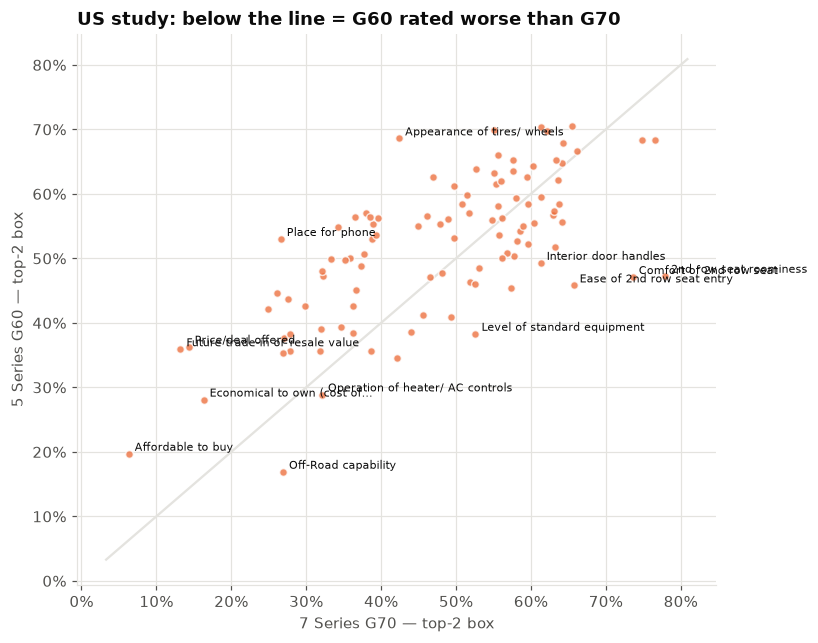

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(s70.loc[s60.index, "top2"], s60["top2"], s=26, color=G60_COLOR, alpha=0.75, edgecolor="white")
lim = [min(s60["top2"].min(), s70["top2"].min()) - 0.03, max(s60["top2"].max(), s70["top2"].max()) + 0.03]
ax.plot(lim, lim, color=GRID, linewidth=1.5, zorder=0)
label = pd.concat([s60.nsmallest(5, "top2_vs_G70"), s60.nlargest(4, "top2_vs_G70"), s60.nsmallest(4, "top2")]).index.unique()
for a in label:
    ax.annotate(short(a, 32), (s70.loc[a, "top2"], s60.loc[a, "top2"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("7 Series G70 — top-2 box")
ax.set_ylabel("5 Series G60 — top-2 box")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("US study: below the line = G60 rated worse than G70")
plt.show()

**Study: findings**

- **Ignore for a sedan:** off-road capability and flat-tire preparedness are the two lowest scores, but they are not
  relevant requirements for a 5 Series. **Out of scope:** affordability, resale, price and cost of ownership (low, but pricing is excluded in the brief).
- **Relevant weak spots:** operation of heater/AC controls (4.80, 15 % bottom-3), infotainment menu structure (4.88),
  Wi-Fi hotspot (4.98), voice recognition (4.99, 16 % bottom-3), placement of controls (5.12), climate control overall
  (5.14) and interior storage (5.15). By domain, **Climate, Controls and HMI** are the weakest product areas.
- **Strongest:** brand prestige (6.07), handling (6.06), driving performance, ride comfort and acceleration. This is the
  same core the verbatims praise.
- **Against the G70:** the G60 is far behind on the **rear seat** (roominess −31 pp top-2, comfort −26 pp, entry −20 pp),
  standard equipment (−14 pp), interior door handles and material quality. It is ahead on phone place, wheels,
  resale, price and bass, which fits a volume car that is good value.
- No sample size is given, so differences of a few points between attributes should not be over-read.

---
## 7. Triangulation: do the verbatims and the study agree?

Each requirement area is an explicit list of VFC feedback topics plus a list of US study attributes. An area has
**converging evidence** when both sources call it weak, and **single-source** evidence when only one does.
Feedback calls an area weak when its net sentiment is below 0. The study calls it weak when its mean is below the median area. The mapping is
hand-made and fully visible. Edit `AREAS` to change it. Pricing / value is left out on purpose (out of scope in the brief).

In [25]:
AREAS = {
    # area: ([VFC feedback topics], [US study attributes])
    "Operating concept & displays": (
        ["Touch screen, operation", "Operating concept, operating system", "Instrument cluster", "Head-Up Display",
         "Center console, front", "Instrument panel", "Controller operation", "Gesture control", "Touch Command",
         "Multi-function steering wheel operation", "Light switch operating unit"],
        ["Intuitiveness of controls", "Placement/ ease of reading and using controls",
         "Overall driver-vehicle interaction (HMI)", "Menu structure of infotainment system",
         "Ease of reading and using screen interface", "Position/ integration of displays in dashboard",
         "Head-up Display"]),
    "Tech complexity & learning": (
        ["Body equipment, overall technology", "Owner's Manual", "Driver profile"],
        ["Technical innovations", "If applicable: Ease of customization"]),
    "Smartphone integration": (
        ["Apple CarPlay", "Android Auto", "Mobile device, wireless charging", "Manage / pair mobile device (Bluetooth)",
         "USB port", "Priorities for telephones"],
        ["Bluetooth/ smartphone pairing", "Mirroring of smartphone content on vehicle display", "Place for phone",
         "Phone charging"]),
    "Connected services, app & nav": (
        ["My BMW App / MINI App", "Remote Software Upgrade/RSU", "Remote Engine Start (My BMW App / MINI App)",
         "Remote Services & Remote Keyless Entry (My BMW App/MINI App)", "Personal eSIM", "WiFi hotspot", "Apps (in-car)",
         "BMW ConnectedDrive upgrades/ MINI CONNECTED upgrades", "ConnectedDrive services (smartphone) technology overall",
         "ConnectedDrive and Infotainment, overall technology", "Navigation", "Teleservices",
         "Remote 3D View (My BMW App / MINI App)", "My BMW / MINI Portal", "Real Time Traffic Information (RTTI)",
         "Smart POI search"],
        ["Vehicle's Mobile App", "WiFi hotspot in vehicle", "If applicable: Navigation system",
         "If applicable: Interactive information system (e.g., OnStar, mbrace, iDrive)"]),
    "Voice assistant": (
        ["Intelligent Personal Assistant", "Intelligent Personal Assistant, activation word",
         "Voice control / speech recognition"],
        ["Performance of voice recognition"]),
    "Climate & heating": (
        ["Vehicle, climatization", "Air conditioning, setting", "Blower function", "Air conditioning control panel",
         "Seating, ventilate / heat", "Heated steering wheel", "Panel heating"],
        ["Operation of heater/ AC controls", "Overall performance of climate control system", "Heater performance",
         "Air conditioner performance"]),
    "Seats": (
        ["Seats", "Interior comfort", "Seat massage", "Seat memory", "Adjustment of lower lumbar support",
         "Headrest, adjust", "Center armrest, front"],
        ["Overall comfort of the seats", "Comfort of front seat", "Comfort of 2nd row seat",
         "Driver seat adjustability", "Passenger seat adjustability"]),
    "Access: keys, doors, trunk": (
        ["non-contact trunk lid opening", "Vehicle, lock / unlock", "Door, open / close", "Vehicle key", "Digital Key",
         "Comfort Access", "Trunk lid, open / close", "Resting state after door opening", "Vehicle, access and exit",
         "Outer door handle, front", "Trunk lid", "Door, front"],
        ["Trunk lid/ tailgate and liftgate operations", "Exterior door handles", "Interior door handles",
         "Ease of front seat entry"]),
    "Storage & cargo": (
        ["Luggage compartment", "Storage compartments", "Glove box", "Cupholder", "Frunk", "Through-loading facility"],
        ["Interior storage", "Cargo capacity/usefulness", "Ease of loading/unloading cargo", "Cupholders"]),
    "Range & charging (EV)": (
        ["Electric Range", "Public charging / external providers", "Charge high-voltage battery",
         "Wallbox, charging / home charging", "Opening/closing charging socket cover", "High voltage battery",
         "High voltage battery, preconditioning", "Charging cable", "Route optimized for charging",
         "High-voltage charging power socket", "Bidirectional charging"],
        ["Gas or electric mileage (fuel economy)", "Overall environmental friendliness"]),
    "Driver assistance": (
        ["Highway assistant", "(Active) cruise control", "Parking Assistant",
         "Driver assistance, automated driving, overall technology", "Lane departure warning", "Surround View",
         "Rear view camera", "Steering and lane guide assist", "Front collision warning", "Blind spot monitoring",
         "Cross Traffic Warning Rear with Brake Intervention", "Speed Limit Assistant", "Back-up Assistant",
         "Fatigue Alert", "Remote controlled parking", "Lane Change Assistant", "Park Distance Control (PDC)",
         "All-round view", "High-beam assistant", "Traffic Light And Sign Warning", "Side View", "Night Vision"],
        ["Overall driver assist features", "Adaptive driving assists (lane keeping, cruise, braking)",
         "Safety monitoring features (blid spot warning, lane departure warning, etc)",
         "If applicable: Backup system (camera, sensors, etc.)"]),
    "Auto start-stop": (
        ["Automatic engine start-stop function (MSA)"],
        []),  # no matching study attribute
    "Drivetrain & performance": (
        ["Drivetrain", "Transmission", "Engine acoustics / engine sound", "My Modes / driving experience",
         "Experience Modes", "Launch Control", "Brake Energy Regeneration / recuperation", "Operate selector lever",
         "Shift paddle"],
        ["Overall power and pickup", "Acceleration from stop", "Passing capability", "Smoothness of transmission",
         "Sound of engine"]),
    "Ride, handling & braking": (
        ["Handling / Riding", "Drive, driving dynamics and chassis, overall technology", "Steering",
         "Cushioning / damping vehicle", "Braking", "Steering wheel", "Self-leveling suspension",
         "Dynamic Stability Control", "Automatic-hold"],
        ["Riding comfort", "Handling/Maneuverability", "Overall driving performance", "Braking", "Turning radius"]),
    "Exterior design": (
        ["Exterior design", "Exterior", "Wheels / tires", "Exterior lighting", "Fog light", "Bumper, rear",
         "Bumper, front", "Exterior rearview mirror"],
        ["Overall exterior styling", "Size/ proportions", "Headlight/ taillight design", "Appearance of tires/ wheels"]),
    "Interior design, space & ambience": (
        ["Interior design", "Ambient light", "Vehicle interior, lighting", "Panorama glass roof",
         "Upholstery / interior trim", "Interior", "Space / spatial impression", "Welcome Light Carpet"],
        ["Overall interior styling/ aesthetics", "Interior lighting", "Quality of interior materials",
         "Overall interior workmanship", "Interior roominess", "If applicable: Sunroof/ moonroof"]),
    "Audio": (
        ["Audio mode, sound", "Radio function", "CD / DVD changer, playback"],
        ["Overall performance of sound system", "Audio clarity", "Bass performance"]),
    "Cabin noise": (
        ["Interior acoustics"],
        ["Overall noise/vibration/harshness", "Freedom from squeaks and rattles", "Freedom from wind and road noise"]),
}

# Sanity checks: every listed topic / attribute must exist, and no topic may sit in two areas.
present = set(cl["topic"])
missing_topics = {t for tps, _ in AREAS.values() for t in tps} - present
missing_attrs = {a for _, attrs in AREAS.values() for a in attrs} - set(s60.index)
all_mapped = [t for tps, _ in AREAS.values() for t in tps]
assert not missing_attrs, missing_attrs
assert len(all_mapped) == len(set(all_mapped)), "topic mapped to two areas"
if missing_topics:
    print("topics listed but absent from US data (ignored):", sorted(missing_topics))

bev_ids = set(feedbacks.loc[feedbacks.powertrain == "BEV", "ID"])
rows = []
for area, (tps, attrs) in AREAS.items():
    r = cl[cl["topic"].isin(tps)]
    ids_pain = r[r.ftype.isin(["Difficult to Use", "Defect"])]["ID"].unique()
    ids_want = r[r.ftype == "Wants"]["ID"].unique()
    ids_like = r[r.ftype == "Likes"]["ID"].unique()
    sev = probs[probs["ID"].isin(r["ID"])]
    rows.append({
        "area": area,
        "feedbacks": r["ID"].nunique(),
        "pain feedbacks": len(ids_pain),
        "wants feedbacks": len(ids_want),
        "likes feedbacks": len(ids_like),
        "net sentiment": (len(ids_like) - len(ids_pain) - len(ids_want)) / max(1, r["ID"].nunique()),
        "BEV share of pain": np.mean([i in bev_ids for i in ids_pain]) if len(ids_pain) else np.nan,
        "serious C reports": int(sev["severity"].isin(["serious", "very serious"]).sum()),
        "study attrs": len(attrs),
        "study mean": s60.loc[attrs, "mean"].mean() if attrs else np.nan,
        "study bottom3": s60.loc[attrs, "bottom3"].mean() if attrs else np.nan,
        "top2 vs G70": s60.loc[attrs, "top2_vs_G70"].mean() if attrs else np.nan,
    })
tri = pd.DataFrame(rows).set_index("area")

# Is this area a problem according to each source? Feedback: more criticism than praise (net < 0).
# Study: mean below the median area (all study means sit in a narrow 5–6 band, so a relative cut is fairer).
fb_problem = tri["net sentiment"] < 0
st_problem = tri["study mean"] < tri["study mean"].median()
tri["agreement"] = np.select(
    [tri["study mean"].isna() & fb_problem, tri["study mean"].isna(),
     fb_problem & st_problem, ~fb_problem & ~st_problem, fb_problem],
    ["feedback weak, no study", "feedback fine, no study", "both: weak", "both: strong", "feedback weak, study fine"],
    default="study weak, feedback fine")
tri.sort_values("net sentiment").style.format({
    "net sentiment": "{:+.2f}", "BEV share of pain": "{:.0%}", "study mean": "{:.2f}", "study bottom3": "{:.1%}",
    "top2 vs G70": "{:+.1%}"}, na_rep="–").background_gradient(subset="net sentiment", cmap="RdBu", vmin=-1, vmax=1) \
    .background_gradient(subset="study mean", cmap="RdBu", vmin=4.9, vmax=5.9)

,feedbacks,pain feedbacks,wants feedbacks,likes feedbacks,net sentiment,BEV share of pain,serious C reports,study attrs,study mean,study bottom3,top2 vs G70,agreement
area,,,,,,,,,,,,
Auto start-stop,36,23,11,2,-0.89,0%,4,0,–,–,–,"feedback weak, no study"
"Access: keys, doors, trunk",226,161,39,33,-0.74,32%,9,4,5.54,3.9%,-5.1%,"feedback weak, study fine"
Smartphone integration,104,77,12,16,-0.70,39%,4,4,5.50,5.7%,+17.8%,both: weak
Climate & heating,116,72,24,21,-0.65,29%,8,4,5.11,8.3%,-1.4%,both: weak
Storage & cargo,81,47,17,17,-0.58,21%,5,4,5.39,5.6%,-0.3%,both: weak
"Connected services, app & nav",198,116,22,60,-0.39,46%,7,4,5.32,6.5%,+11.7%,both: weak
Range & charging (EV),220,121,34,71,-0.38,86%,7,2,5.48,5.0%,+14.4%,both: weak
Audio,58,27,15,20,-0.38,48%,1,3,5.59,3.9%,+18.2%,"feedback weak, study fine"
Driver assistance,258,125,43,91,-0.30,30%,5,4,5.72,1.6%,+4.4%,"feedback weak, study fine"


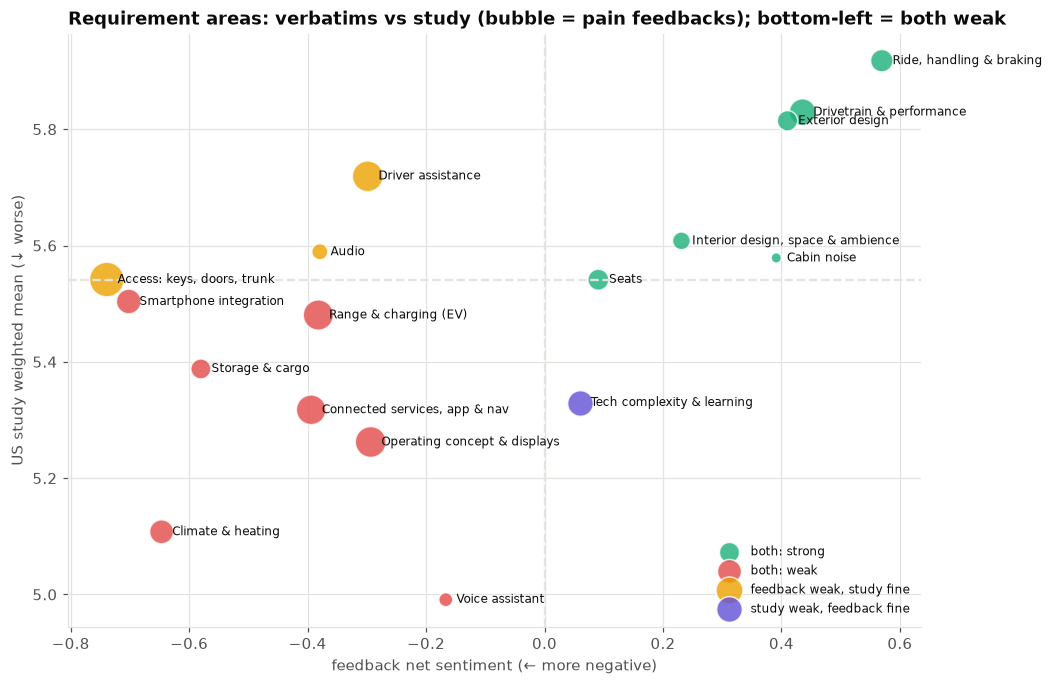

**Mapping coverage:** 90% of classified rows fall into an area. Largest unmapped topics:

topic,Impression of safety,Vehicle battery,Seat belts,"Door, finisher panel, front",Drive Recorder,"Interior mirror, garage door opener",ground clearance,RSC tire
ftype,,,,,,,,
total,16.00,15.00,14.00,13.00,11.00,11.00,11.00,10.00
net_sentiment,0.38,-0.47,-0.71,-0.54,-0.45,-0.64,-0.82,-0.80


In [26]:
fig, ax = plt.subplots(figsize=(10, 7))
colors = {"both: weak": "#e34948", "both: strong": "#1baf7a", "feedback weak, study fine": "#eda100",
          "study weak, feedback fine": "#6250d6"}
plot = tri.dropna(subset=["study mean"])
for ag, g in plot.groupby("agreement"):
    ax.scatter(g["net sentiment"], g["study mean"], s=g["pain feedbacks"].clip(lower=5) * 3 + 30, color=colors[ag],
               label=ag, alpha=0.8, edgecolor="white")
for a, r in plot.iterrows():
    ax.annotate(a, (r["net sentiment"], r["study mean"]), fontsize=8, xytext=(7, 0), textcoords="offset points", va="center")
ax.axvline(0, color=GRID, linestyle="--")
ax.axhline(tri["study mean"].median(), color=GRID, linestyle="--")
ax.set_xlabel("feedback net sentiment (← more negative)")
ax.set_ylabel("US study weighted mean (↓ worse)")
ax.set_title("Requirement areas: verbatims vs study (bubble = pain feedbacks); bottom-left = both weak")
ax.legend(loc="lower right", fontsize=8)
plt.show()

unmapped = topics.loc[~topics.index.isin(all_mapped)].head(15)
display(Markdown(f"**Mapping coverage:** {cl['topic'].isin(all_mapped).mean():.0%} of classified rows fall into an area. "
                 "Largest unmapped topics:"))
unmapped[["total", "net_sentiment"]].T.style.format("{:.2f}")

---
## 8. Evidence scorecard: a first, explainable priority order

A deliberately simple, transparent score to seed the PM discussion. It is **not** a final prioritisation. Each
component is turned into a 0–1 percentile rank across the areas, then weighted:

| Component | Weight | Why |
| --- | ---: | --- |
| Pain feedbacks (DtU + Defect) | 0.30 | How many customers hit the problem |
| Wants feedbacks | 0.15 | Explicit demand for change |
| Serious / very serious Source C reports | 0.15 | Customer-rated severity |
| Study bottom-3 box | 0.25 | Rejection in a structured survey |
| Gap to G70 (top-2, negative = behind) | 0.15 | Headroom shown by BMW's own flagship |

An area with no study attribute gets a neutral 0.5 on the study components. Strengths with high Likes and good study scores are listed separately as **protect** areas: the successor must not
lose them.

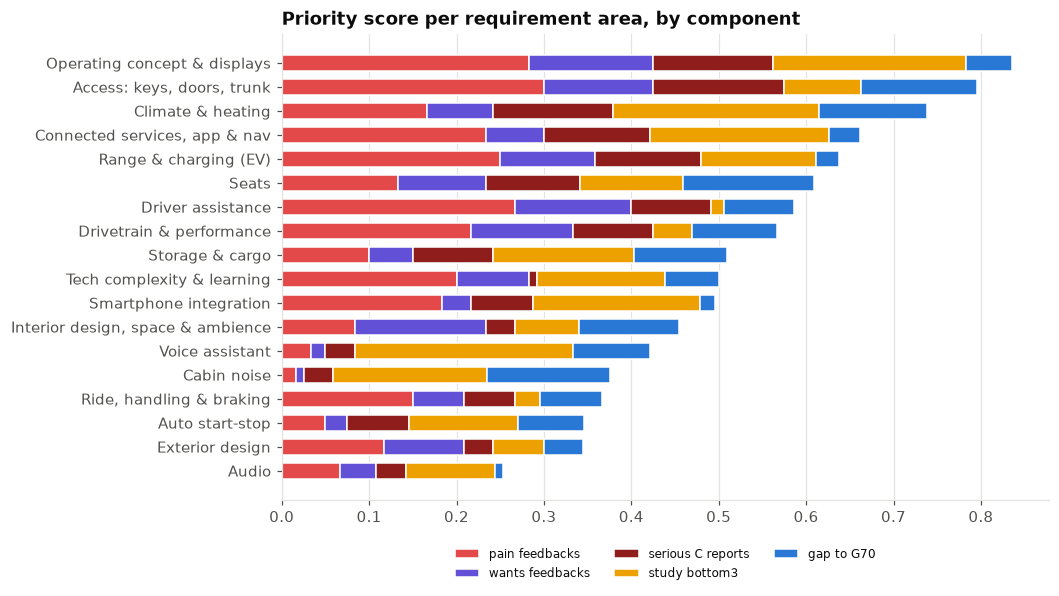

,priority score,evidence,agreement,pain feedbacks,wants feedbacks,serious C reports,study mean,study bottom3,top2 vs G70,BEV share of pain
area,,,,,,,,,,
Operating concept & displays,0.84,converging,both: weak,126,45,8,5.26,7.6%,+10.2%,35%
"Access: keys, doors, trunk",0.80,single-source,"feedback weak, study fine",161,39,9,5.54,3.9%,-5.1%,32%
Climate & heating,0.74,converging,both: weak,72,24,8,5.11,8.3%,-1.4%,29%
"Connected services, app & nav",0.66,converging,both: weak,116,22,7,5.32,6.5%,+11.7%,46%
Range & charging (EV),0.64,converging,both: weak,121,34,7,5.48,5.0%,+14.4%,86%
Seats,0.61,—,both: strong,53,32,6,5.54,4.4%,-7.0%,32%
Driver assistance,0.59,single-source,"feedback weak, study fine",125,43,5,5.72,1.6%,+4.4%,30%
Drivetrain & performance,0.57,—,both: strong,91,36,5,5.83,2.5%,+0.2%,33%
Storage & cargo,0.51,converging,both: weak,47,17,5,5.39,5.6%,-0.3%,21%


In [27]:
WEIGHTS = {"pain feedbacks": 0.30, "wants feedbacks": 0.15, "serious C reports": 0.15,
           "study bottom3": 0.25, "gap to G70": 0.15}
score_in = tri.assign(**{"gap to G70": -tri["top2 vs G70"]})
pct = score_in[list(WEIGHTS)].rank(pct=True).fillna(0.5)
tri["priority score"] = sum(pct[k] * w for k, w in WEIGHTS.items())
tri["evidence"] = np.select(
    [tri["agreement"] == "both: weak", tri["agreement"].str.contains("weak")],
    ["converging", "single-source"], default="—")

fix = tri.sort_values("priority score", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
contrib = (pct * pd.Series(WEIGHTS)).loc[fix.index].iloc[::-1]
left = np.zeros(len(contrib))
for k, col in zip(WEIGHTS, ["#e34948", "#6250d6", "#8f1d1c", "#eda100", "#2a78d6"]):
    ax.barh(contrib.index, contrib[k], left=left, color=col, label=k, height=0.65, edgecolor="white")
    left += contrib[k].values
ax.set_title("Priority score per requirement area, by component")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8)
ax.grid(axis="y", visible=False)
plt.show()

fix[["priority score", "evidence", "agreement", "pain feedbacks", "wants feedbacks", "serious C reports",
     "study mean", "study bottom3", "top2 vs G70", "BEV share of pain"]].style.format({
    "priority score": "{:.2f}", "study mean": "{:.2f}", "study bottom3": "{:.1%}", "top2 vs G70": "{:+.1%}",
    "BEV share of pain": "{:.0%}"}, na_rep="–").bar(subset="priority score", color="#f8c9ae", vmin=0, vmax=1)

In [28]:
protect = tri.assign(like_rank=tri["likes feedbacks"].rank(pct=True), study_rank=tri["study mean"].rank(pct=True))
protect["protect score"] = (protect["like_rank"] + protect["study_rank"]) / 2
display(Markdown("**Protect: strengths the successor must keep**"))
protect.sort_values("protect score", ascending=False).head(6)[
    ["protect score", "likes feedbacks", "net sentiment", "study mean", "top2 vs G70"]].style.format(
    {"protect score": "{:.2f}", "net sentiment": "{:+.2f}", "study mean": "{:.2f}", "top2 vs G70": "{:+.1%}"})

**Protect: strengths the successor must keep**

,protect score,likes feedbacks,net sentiment,study mean,top2 vs G70
area,,,,,
"Ride, handling & braking",0.97,292,+0.57,5.92,+6.9%
Drivetrain & performance,0.97,320,+0.44,5.83,+0.2%
Exterior design,0.89,182,+0.41,5.81,+10.9%
"Interior design, space & ambience",0.80,131,+0.23,5.61,-0.9%
Driver assistance,0.72,91,-0.30,5.72,+4.4%
Seats,0.63,101,+0.09,5.54,-7.0%


In [29]:
# Export the area-level evidence so the app / slides can reuse it.
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
tri.reset_index().to_csv(OUT / "g60_us_requirement_areas.csv", index=False)
s60.reset_index().to_csv(OUT / "g60_us_study_attributes.csv", index=False)
topics.reset_index().to_csv(OUT / "g60_us_feedback_topics.csv", index=False)
print("wrote", *sorted(p.name for p in OUT.glob("g60_us_*.csv")), sep="\n  ")

wrote
  g60_us_feedback_topics.csv
  g60_us_requirement_areas.csv
  g60_us_study_attributes.csv


---
## 9. Summary: what the US 5 Series data says

**Market.** About 78k units a year, flat to 2030, 87 % of the challenge-series volume in the US. This is a defend-and-retain market,
and the one with by far the richest 5 Series customer evidence (3,610 feedbacks + a 103-attribute study).

**Candidate requirement areas (fix)**, in the order of the §8 score. Evidence type in brackets:

1. **Operating concept & displays** (converging): menu structure, control placement and touch-only operation; worst study domain
   besides climate; 126 pain feedbacks.
2. **Access: keys, doors, trunk** (feedback only): non-contact trunk opening that works less than half the time,
   lock/unlock, Comfort Access and the digital key. These are the most one-sided negative topics, and Source C's top
   item by severity score.
3. **Climate & heating** (converging): heater/AC controls are among the lowest-rated attributes in the study and
   "poorly located" in Source C.
4. **Connected services, app & navigation** (converging): app, Wi-Fi hotspot, remote services and software upgrades.
5. **Range & charging, i5 only** (converging): 86 % of pain is from BEV owners; customers ask for about 400 miles and
   reliable public DC charging.

Also worth a requirement: **storage & cargo** and **smartphone integration** (converging, smaller), the **voice assistant**
(lowest study score, little feedback), and **auto start-stop** (a strong, ICE-only request for a permanent off switch).

**Protect:** ride & handling, drivetrain & performance and exterior design score best in both sources.

**Headroom vs the 7 Series:** rear-seat space and comfort, standard equipment and interior material quality.

**Limits of this evidence:** feedback is 73 % dealer/call-centre paraphrase, and its powertrain mix is not the sales mix.
The study has no sample size, sales have no powertrain split, and the priority score is a transparent starting point for
the PM to adjust, not a verdict. It rewards areas with many complaints, so large areas such as drivetrain rank mid-table
although they are strengths.